# Sistem Analisis Fase Pertumbuhan Larva Black Soldier Fly (BSF)
## Notebook Lengkap dengan Penjelasan Teknis Mendalam

Notebook ini berisi seluruh pipeline proyek, disusun mengikuti alur: **pengumpulan data -> preprocessing data -> ekstraksi fitur -> pelatihan model -> pengujian -> klasifikasi**. Setiap tahap disertai penjelasan konsep, arsitektur, dan formula matematis yang mendasarinya, agar notebook ini juga berfungsi sebagai dokumentasi teknis skripsi.

### Daftar Isi
1. Setup & Import
2. Pengumpulan Data
3. Preprocessing Data (Remapping Kelas, Split, Normalisasi, Letterbox, Augmentasi)
4. **Ekstraksi Fitur** (Arsitektur YOLOv11 & Modul Ciri Visual — Warna/K-Means, Tekstur/Laplacian)
5. Pelatihan Model (Training YOLOv11s)
6. Pengujian (Evaluasi Model)
7. **Klasifikasi** (Rekomendasi Panen & Pipeline Analisis Terintegrasi)
8. Ekspor Model ke TensorFlow Lite

---

---
## 1. Setup Awal & Import Library

Sebelum memulai, kita import seluruh library yang dibutuhkan sepanjang pipeline:

- **`ultralytics`** — framework resmi untuk YOLOv11 (training, validasi, ekspor)
- **`opencv-python (cv2)`** — pengolahan citra (thresholding, K-Means, konvolusi Laplacian)
- **`numpy`** — operasi numerik/array
- **`pandas`** — analisis data tabular
- **`matplotlib`** — visualisasi
- **`torch`** — backend deep learning yang dipakai Ultralytics (dengan dukungan CUDA/GPU)


In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  

import sys
import shutil
import random
import json
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import torch

PROJECT_ROOT = Path(".")
SPLITS = ["train", "valid", "test"]
CLASS_NAMES = ["Larva Muda", "Larva Dewasa", "Prepupa", "Pupa"]

print("CUDA tersedia:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


CUDA tersedia: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


---
## 2. Pengumpulan Data

Dataset yang digunakan adalah **Black Soldier Fly Larvae Computer Vision Dataset** dari Roboflow Universe. Dataset asli memiliki **6 kelas instar** (class_id 0-5) yang kemudian dipetakan ulang menjadi **4 fase pertumbuhan** berdasarkan analisis visual (warna, tekstur, dan bentuk tubuh larva):

| Fase | Ciri Visual |
|---|---|
| Larva Muda | Ramping, warna pucat/krem, badan tipis |
| Larva Dewasa | Gemuk, oval, warna oranye-coklat, segmen jelas |
| Prepupa | Sangat gemuk, halus, oranye pekat, bentuk kompak |
| Pupa | Hitam pekat, keras, bentuk kapsul |


In [2]:
DATA_RAW = PROJECT_ROOT / "data" / "raw"

paths = {
    split: {
        "images": DATA_RAW / split / "images",
        "labels": DATA_RAW / split / "labels",
    }
    for split in SPLITS
}

def read_yolo_label(label_path):
    with open(label_path, "r") as f:
        return [line.strip().split() for line in f.readlines() if line.strip()]

def get_class_distribution(labels_folder):
    counter = Counter()
    for label_file in Path(labels_folder).glob("*.txt"):
        for row in read_yolo_label(label_file):
            counter[int(row[0])] += 1
    return counter

for split in SPLITS:
    n_img = len(list(paths[split]["images"].glob("*.*")))
    n_lbl = len(list(paths[split]["labels"].glob("*.txt")))
    dist = get_class_distribution(paths[split]["labels"])
    dist_named = {CLASS_NAMES[k]: v for k, v in sorted(dist.items()) if k < len(CLASS_NAMES)}
    print(f"[{split.upper()}] images={n_img} labels={n_lbl} dist={dist_named}")


[TRAIN] images=20049 labels=20049 dist={'Larva Muda': 8649, 'Larva Dewasa': 8798, 'Prepupa': 4275, 'Pupa': 4081}
[VALID] images=1347 labels=1347 dist={'Larva Muda': 476, 'Larva Dewasa': 553, 'Prepupa': 315, 'Pupa': 279}
[TEST] images=578 labels=578 dist={'Larva Muda': 380, 'Larva Dewasa': 358, 'Prepupa': 109, 'Pupa': 115}


In [3]:
from collections import Counter

def hitung_jumlah_larva_per_fase(labels_folder):
    """Menghitung jumlah instance larva per kelas fase dari seluruh file label pada satu folder."""
    counter = Counter()
    for label_path in labels_folder.glob("*.txt"):
        rows = read_yolo_label(label_path)
        for row in rows:
            class_id = int(row[0])
            counter[class_id] += 1
    return counter

counter_train = hitung_jumlah_larva_per_fase(paths["train"]["labels"])
counter_valid = hitung_jumlah_larva_per_fase(paths["valid"]["labels"])
counter_test = hitung_jumlah_larva_per_fase(paths["test"]["labels"])

print(f"{'Fase':<15}{'Train':>10}{'Valid':>14}{'Test':>10}{'Total':>10}")
print("-" * 59)

total_train = total_valid = total_test = 0   # <-- PERBAIKAN DI SINI
for class_id, fase_nama in enumerate(CLASS_NAMES):
    n_train = counter_train.get(class_id, 0)
    n_valid = counter_valid.get(class_id, 0)
    n_test = counter_test.get(class_id, 0)
    n_total = n_train + n_valid + n_test

    total_train += n_train
    total_valid += n_valid
    total_test += n_test

    print(f"{fase_nama:<15}{n_train:>10}{n_valid:>14}{n_test:>10}{n_total:>10}")

print("-" * 59)
print(f"{'Total':<15}{total_train:>10}{total_valid:>14}{total_test:>10}{total_train+total_valid+total_test:>10}")

Fase                Train         Valid      Test     Total
-----------------------------------------------------------
Larva Muda           8649           476       380      9505
Larva Dewasa         8798           553       358      9709
Prepupa              4275           315       109      4699
Pupa                 4081           279       115      4475
-----------------------------------------------------------
Total               25803          1623       962     28388


---
## 3. Preprocessing Data

Preprocessing pada proyek ini terbagi menjadi beberapa tahap yang **wajib dilakukan secara berurutan**:

### 3.1 Remapping Kelas (6 Instar -> 4 Fase)
Label asli dataset memakai `class_id` 0-5 (instar). Kita petakan ulang secara **permanen** ke file anotasi `.txt` (format YOLO: `class_id x_center y_center width height`, seluruhnya ternormalisasi 0-1 terhadap ukuran gambar), sebelum backup dibuat terlebih dahulu.

### 3.2 Pembagian Dataset (Train/Valid/Test)
Memakai pembagian bawaan Roboflow: 91,24% train, 6,13% valid, 2,63% test dari total 21.974 citra.

### 3.3 Normalisasi Piksel
Setiap piksel citra dinormalisasi dari rentang [0, 255] menjadi [0, 1] dengan membagi nilai piksel dengan 255. Ini bagian dari preprocessing internal YOLO, dilakukan otomatis oleh Ultralytics saat training/inference.

### 3.4 Resize dengan Letterbox
Karena ukuran gambar asli bervariasi, YOLO membutuhkan ukuran citra yang seragam (640x640). Teknik **letterbox** dipakai agar rasio aspek asli citra tidak berubah (tidak ada distorsi):
1. Hitung skala: `scale = min(640/W, 640/H)`
2. Resize citra dengan skala tersebut
3. Tempatkan hasil resize di tengah kanvas 640x640 berwarna abu-abu (114,114,114), sisanya diisi padding

Ini penting karena tanpa letterbox, resize langsung ke 640x640 akan meregangkan/mengompresi objek secara tidak proporsional, merusak bentuk larva yang jadi kunci klasifikasi fase.

In [4]:
CLASS_ID_TO_PHASE = {
    0: "Larva Muda", 1: "Larva Muda",
    2: "Larva Dewasa", 3: "Larva Dewasa",
    4: "Prepupa",
    5: "Pupa",
}
PHASE_TO_NEW_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
OLD_TO_NEW_ID = {old_id: PHASE_TO_NEW_ID[phase] for old_id, phase in CLASS_ID_TO_PHASE.items()}
print("Mapping class_id lama -> baru:", OLD_TO_NEW_ID)

def is_already_remapped(labels_folder):
    dist = get_class_distribution(labels_folder)
    return len(dist) > 0 and max(dist.keys(), default=-1) <= 3

def remap_labels_inplace(labels_folder):
    count = 0
    for label_file in Path(labels_folder).glob("*.txt"):
        rows = read_yolo_label(label_file)
        new_rows = []
        for row in rows:
            old_id = int(row[0])
            new_id = OLD_TO_NEW_ID.get(old_id, old_id)
            new_rows.append(" ".join([str(new_id)] + row[1:]))
        with open(label_file, "w") as f:
            f.write("\n".join(new_rows) + "\n")
        count += 1
    return count

# Backup otomatis sebelum remap, dan skip jika sudah pernah di-remap (mencegah remap ganda)
for split in SPLITS:
    labels_folder = paths[split]["labels"]
    backup_folder = labels_folder.parent / "labels_original_backup"
    if not backup_folder.exists():
        shutil.copytree(str(labels_folder), str(backup_folder))
        print(f"[{split}] backup dibuat.")
    if is_already_remapped(labels_folder):
        print(f"[{split}] sudah dalam format 4 kelas, dilewati.")
        continue
    n = remap_labels_inplace(labels_folder)
    print(f"[{split}] {n} file berhasil di-remap.")


Mapping class_id lama -> baru: {0: 0, 1: 0, 2: 1, 3: 1, 4: 2, 5: 3}
[train] sudah dalam format 4 kelas, dilewati.
[valid] sudah dalam format 4 kelas, dilewati.
[test] sudah dalam format 4 kelas, dilewati.


Ukuran asli: (640, 640)
Skala: 1.0000, padding: (0, 0)
Ukuran setelah letterbox: (640, 640)
Rentang nilai piksel setelah normalisasi: [0.114, 1.000]


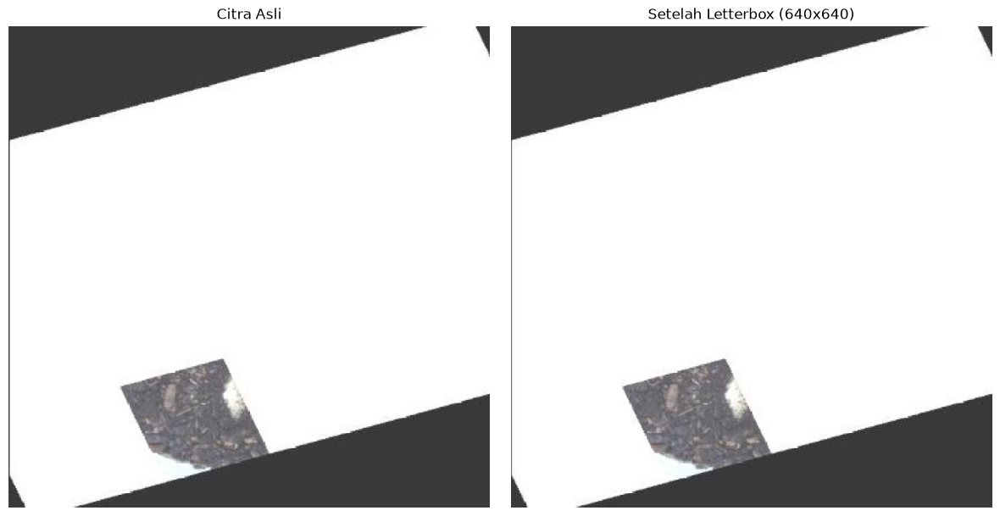

In [5]:
# Fungsi letterbox preprocessing (diilustrasikan secara manual di sini,
# meskipun saat training Ultralytics menjalankannya otomatis secara internal)
def letterbox_preprocess(image, target_size=640, pad_color=(114, 114, 114)):
    """
    Resize citra secara proporsional (mempertahankan rasio aspek), lalu
    tempatkan di tengah kanvas target_size x target_size dengan padding abu-abu.
    """
    h, w = image.shape[:2]
    scale = min(target_size / w, target_size / h)
    new_w, new_h = int(w * scale), int(h * scale)
    resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    canvas = np.full((target_size, target_size, 3), pad_color, dtype=np.uint8)
    pad_x = (target_size - new_w) // 2
    pad_y = (target_size - new_h) // 2
    canvas[pad_y:pad_y+new_h, pad_x:pad_x+new_w] = resized

    return canvas, scale, pad_x, pad_y

def normalize_pixels(image):
    """Normalisasi nilai piksel dari rentang [0,255] ke [0,1] (float32)."""
    return image.astype(np.float32) / 255.0

# Demo preprocessing pada satu contoh gambar
sample_img_path = random.choice(list(paths["train"]["images"].glob("*.*")))
img = cv2.imread(str(sample_img_path))
letterboxed, scale, pad_x, pad_y = letterbox_preprocess(img)
normalized = normalize_pixels(letterboxed)

print(f"Ukuran asli: {img.shape[:2]}")
print(f"Skala: {scale:.4f}, padding: ({pad_x}, {pad_y})")
print(f"Ukuran setelah letterbox: {letterboxed.shape[:2]}")
print(f"Rentang nilai piksel setelah normalisasi: [{normalized.min():.3f}, {normalized.max():.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title("Citra Asli"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(letterboxed, cv2.COLOR_BGR2RGB)); axes[1].set_title("Setelah Letterbox (640x640)"); axes[1].axis("off")
plt.tight_layout(); plt.show()


Citra sampel: -_jpg.rf.400e05222c259011470d1261082c2db1.jpg
Ukuran asli: 640x640 piksel
Ukuran setelah letterbox resizing: 640x640 piksel
Scale factor: 1.0000
Padding (x, y): (0, 0)
Rentang nilai piksel sebelum normalisasi: [0, 255]
Rentang nilai piksel setelah normalisasi: [0.0000, 1.0000]


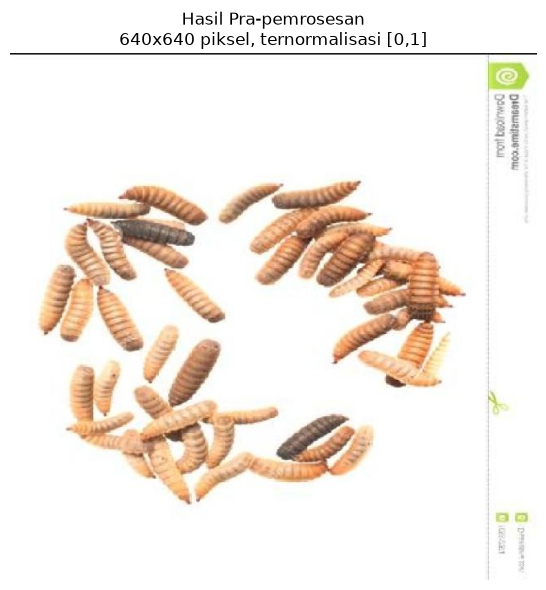


Isi file label (class_id sudah dalam bentuk 4 fase, hasil remapping):
1 0.1296875 0.4890625 0.0671875 0.125
1 0.13125 0.64453125 0.053125 0.1203125
1 0.165625 0.703125 0.1296875 0.05546875
1 0.18046875 0.29296875 0.178125 0.03359375
1 0.1828125 0.63203125 0.053125 0.10078125
2 0.1921875 0.37109375 0.10546875 0.115625
1 0.1921875 0.734375 0.14453125 0.040625
2 0.2078125 0.5046875 0.08671875 0.1296875
3 0.271875 0.3390625 0.15390625 0.053125
2 0.271875 0.3734375 0.1390625 0.0625
1 0.2765625 0.56953125 0.084375 0.1109375
2 0.27890625 0.6875 0.09609375 0.115625
2 0.28515625 0.28359375 0.1734375 0.08203125
1 0.2921875 0.78125 0.09140625 0.146875
1 0.3171875 0.69453125 0.15625 0.0765625
2 0.34609375 0.45546875 0.125 0.10546875
2 0.35078125 0.60546875 0.0984375 0.1296875
1 0.4046875 0.80078125 0.125 0.0984375
2 0.4515625 0.2859375 0.134375 0.0890625
2 0.50390625 0.33203125 0.125 0.084375
2 0.5140625 0.39453125 0.084375 0.10078125
1 0.52890625 0.7796875 0.16328125 0.053125
3 0.56953125 0.7210

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ambil satu sampel citra dari data latih
sample_img_path = list(paths["train"]["images"].glob("*.*"))[0]
img_asli = cv2.imread(str(sample_img_path))

print(f"Citra sampel: {sample_img_path.name}")
print(f"Ukuran asli: {img_asli.shape[1]}x{img_asli.shape[0]} piksel")

# --- Tahap 1: Letterbox resizing ke 640x640 ---
img_letterbox, scale, pad_x, pad_y = letterbox_preprocess(img_asli, target_size=640)
print(f"Ukuran setelah letterbox resizing: {img_letterbox.shape[1]}x{img_letterbox.shape[0]} piksel")
print(f"Scale factor: {scale:.4f}")
print(f"Padding (x, y): ({pad_x}, {pad_y})")

# --- Tahap 2: Normalisasi piksel ke rentang [0, 1] ---
img_normalized = img_letterbox.astype(np.float32) / 255.0
print(f"Rentang nilai piksel sebelum normalisasi: [{img_letterbox.min()}, {img_letterbox.max()}]")
print(f"Rentang nilai piksel setelah normalisasi: [{img_normalized.min():.4f}, {img_normalized.max():.4f}]")

# --- Tampilkan hasil akhir (sesudah pra-pemrosesan) ---
img_rgb = cv2.cvtColor(img_letterbox, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title(f"Hasil Pra-pemrosesan\n640x640 piksel, ternormalisasi [0,1]", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.savefig("outputs/gambar_4_x_hasil_preprocessing.png", dpi=200, bbox_inches="tight")
plt.show()
label_path = paths["train"]["labels"] / f"{sample_img_path.stem}.txt"
if label_path.exists():
    print("\nIsi file label (class_id sudah dalam bentuk 4 fase, hasil remapping):")
    with open(label_path) as f:
        print(f.read())

### 3.5 Visualisasi 6 Kelas Instar Asli (Sebelum Remapping)

Sel berikut membaca folder `labels_original_backup` (anotasi sebelum remap) untuk menampilkan contoh visual tiap `class_id` asli (0-5). Sel ini bersifat **read-only** terhadap data backup, tidak mengubah proses remapping maupun label aktif yang sudah dipakai untuk training.

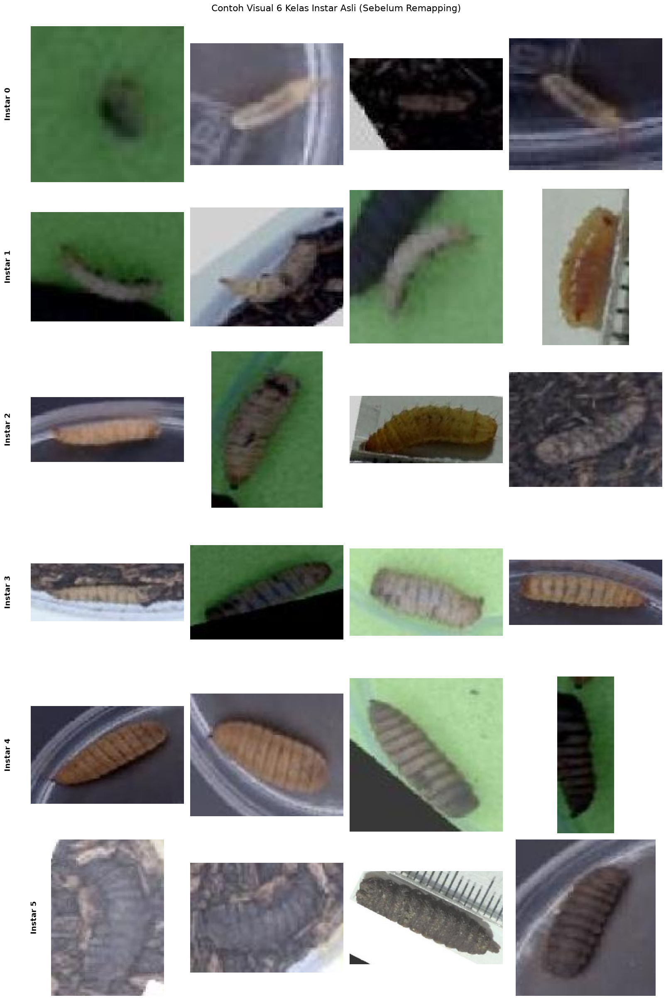

In [7]:
def get_crops_for_class_original(target_class, images_folder, backup_labels_folder, n_samples=4, seed=42):
    """Ambil crop larva berdasarkan class_id ASLI (dari backup, bukan hasil remap)."""
    random.seed(seed)
    label_files = list(Path(backup_labels_folder).glob("*.txt"))
    random.shuffle(label_files)
    crops = []
    for label_file in label_files:
        if len(crops) >= n_samples:
            break
        rows = read_yolo_label(label_file)
        matching = [r for r in rows if int(r[0]) == target_class]
        if not matching:
            continue
        img_path = Path(images_folder) / f"{label_file.stem}.jpg"
        if not img_path.exists():
            img_path = Path(images_folder) / f"{label_file.stem}.png"
        if not img_path.exists():
            continue
        img = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        xc, yc, bw, bh = map(float, matching[0][1:5])
        x1, y1, x2, y2 = int((xc-bw/2)*w), int((yc-bh/2)*h), int((xc+bw/2)*w), int((yc+bh/2)*h)
        pad = 15
        x1c, y1c = max(x1-pad,0), max(y1-pad,0)
        x2c, y2c = min(x2+pad,w), min(y2+pad,h)
        crops.append(img_rgb[y1c:y2c, x1c:x2c])
    return crops

backup_labels_train = paths["train"]["labels"].parent / "labels_original_backup"
SAMPLES_PER_INSTAR = 4

if backup_labels_train.exists():
    fig, axes = plt.subplots(6, SAMPLES_PER_INSTAR, figsize=(4*SAMPLES_PER_INSTAR, 4*6))
    for row_idx in range(6):
        crops = get_crops_for_class_original(row_idx, paths["train"]["images"], backup_labels_train, SAMPLES_PER_INSTAR)
        for col_idx in range(SAMPLES_PER_INSTAR):
            ax = axes[row_idx, col_idx]
            if col_idx < len(crops):
                ax.imshow(crops[col_idx])
            ax.axis("off")
        axes[row_idx, 0].text(-0.15, 0.5, f"Instar {row_idx}", fontsize=13, fontweight="bold",
                               rotation=90, va="center", ha="center", transform=axes[row_idx,0].transAxes)
    plt.suptitle("Contoh Visual 6 Kelas Instar Asli (Sebelum Remapping)", fontsize=16, y=1.0)
    plt.tight_layout()
    Path("outputs").mkdir(exist_ok=True)
    plt.savefig("outputs/grid_6_instar_asli.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Folder labels_original_backup tidak ditemukan. Jalankan sel remapping (Bagian 3) terlebih dahulu.")


In [8]:
def get_one_crop_per_class(target_class, images_folder, labels_folder, seed=42):
    random.seed(seed)
    label_files = list(Path(labels_folder).glob("*.txt"))
    random.shuffle(label_files)
    for label_file in label_files:
        rows = read_yolo_label(label_file)
        matching = [r for r in rows if int(r[0]) == target_class]
        if not matching:
            continue
        img_path = Path(images_folder) / f"{label_file.stem}.jpg"
        if not img_path.exists():
            img_path = Path(images_folder) / f"{label_file.stem}.png"
        if not img_path.exists():
            continue
        img = cv2.imread(str(img_path))
        h, w = img.shape[:2]
        xc, yc, bw, bh = map(float, matching[0][1:5])
        x1, y1, x2, y2 = int((xc-bw/2)*w), int((yc-bh/2)*h), int((xc+bw/2)*w), int((yc+bh/2)*h)
        pad = 15
        x1c, y1c = max(x1-pad,0), max(y1-pad,0)
        x2c, y2c = min(x2+pad,w), min(y2+pad,h)
        return img[y1c:y2c, x1c:x2c]
    return None

C:\Users\Ikhwan Maulana\AppData\Local\Temp\ipykernel_30392\1004748712.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


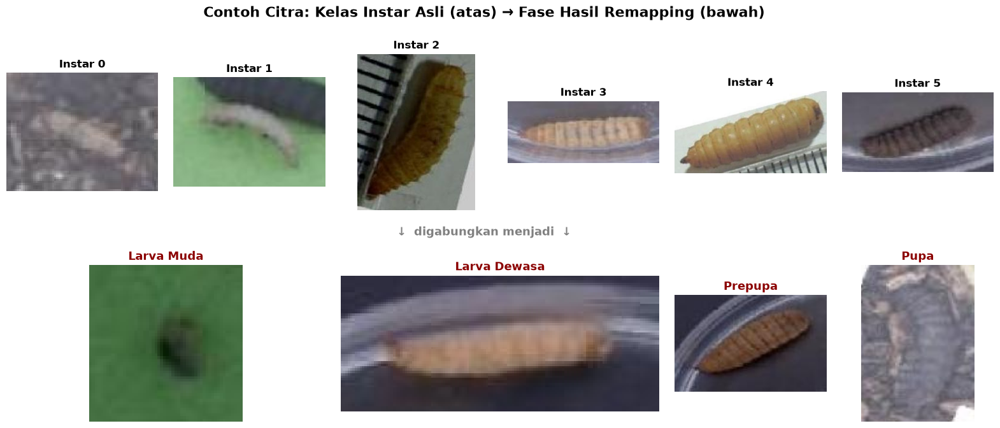

In [9]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cv2

# ============================================================
# Seed terpilih (hasil eksplorasi) untuk gambar paling jelas per instar
# ============================================================
seed_terpilih = {0: 1, 1: 21, 2: 21, 3: 99, 4: 99, 5: 1}

contoh_per_instar = {}
for instar_id, seed in seed_terpilih.items():
    crops = get_crops_for_class_original(
        target_class=instar_id,
        images_folder=paths["train"]["images"],
        backup_labels_folder=paths["train"]["labels"].parent / "labels_original_backup",
        n_samples=1,
        seed=seed,
    )
    if crops:
        contoh_per_instar[instar_id] = crops[0]  # sudah RGB, tidak perlu cvtColor lagi

# ============================================================
# Contoh crop per FASE hasil remapping
# ============================================================
contoh_per_fase = {}
for fase_id, fase_nama in enumerate(CLASS_NAMES):
    crop = get_one_crop_per_class(fase_id, paths["train"]["images"], paths["train"]["labels"], seed=42)
    if crop is not None and crop.size > 0:
        contoh_per_fase[fase_nama] = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)  # fungsi ini return BGR, perlu convert

pemetaan = {0: "Larva Muda", 1: "Larva Muda", 2: "Larva Dewasa", 3: "Larva Dewasa", 4: "Prepupa", 5: "Pupa"}

fig = plt.figure(figsize=(20, 7.5))
gs = gridspec.GridSpec(2, 6, height_ratios=[1, 1], hspace=0.35, wspace=0.1)

for i in range(6):
    ax = fig.add_subplot(gs[0, i])
    if i in contoh_per_instar:
        ax.imshow(contoh_per_instar[i])
    ax.set_title(f"Instar {i}", fontsize=12, fontweight="bold")
    ax.axis("off")

posisi_kolom = {"Larva Muda": (0, 2), "Larva Dewasa": (2, 2), "Prepupa": (4, 1), "Pupa": (5, 1)}
for fase_nama, (mulai, lebar) in posisi_kolom.items():
    ax = fig.add_subplot(gs[1, mulai:mulai + lebar])
    if fase_nama in contoh_per_fase:
        ax.imshow(contoh_per_fase[fase_nama])
    ax.set_title(fase_nama, fontsize=13, fontweight="bold", color="darkred")
    ax.axis("off")

fig.text(0.5, 0.5, "↓  digabungkan menjadi  ↓", ha="center", fontsize=13, fontweight="bold", color="gray")

plt.suptitle("Contoh Citra: Kelas Instar Asli (atas) → Fase Hasil Remapping (bawah)",
             fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("outputs/contoh_before_after_remapping_final.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

### 3.6 Augmentasi Data

Augmentasi dilakukan **on-the-fly** oleh Ultralytics setiap kali sebuah batch data diambil saat training, bukan disimpan sebagai file baru. Berikut penjelasan tiap teknik augmentasi yang dipakai dan alasan pemilihannya:

| Parameter | Nilai | Penjelasan |
|---|---|---|
| `hsv_h` | 0.015 | Menggeser *hue* (warna) sedikit, agar model tak terlalu sensitif pada nuansa warna spesifik |
| `hsv_s` | 0.7 | Variasi saturasi tinggi — penting karena background dataset bervariasi drastis (tanah, plastik) |
| `hsv_v` | 0.4 | Variasi kecerahan — mengakomodasi variasi kondisi pencahayaan saat foto diambil |
| `degrees` | 15.0 | Rotasi acak ±15° — larva difoto dari berbagai sudut |
| `translate` | 0.1 | Pergeseran posisi objek dalam frame |
| `scale` | 0.5 | Variasi zoom in/out, mensimulasikan larva difoto dari jarak berbeda |
| `fliplr` | 0.5 | Flip horizontal (probabilitas 50%) |
| `flipud` | 0.3 | Flip vertikal (larva tidak punya orientasi atas-bawah yang kaku) |
| `mosaic` | 1.0 | Menggabungkan 4 citra jadi 1 — sangat efektif untuk deteksi objek kecil dalam frame besar |
| `mixup` | 0.1 | Interpolasi linear dua citra + label sekaligus (augmentasi tingkat citra, bukan objek) |
| `copy_paste` | 0.1 | Menyalin objek dari satu citra ke citra lain — membantu kelas minoritas (Prepupa, Pupa) muncul lebih variatif |

**Mixup** secara matematis didefinisikan sebagai:

$$\tilde{x} = \lambda x_i + (1-\lambda) x_j, \quad \tilde{y} = \lambda y_i + (1-\lambda) y_j$$

dengan $\lambda$ diambil dari distribusi Beta$(\alpha, \alpha)$, $x_i, x_j$ dua citra berbeda, dan $y_i, y_j$ label keduanya.

In [10]:
AUGMENTATION_CONFIG = {
    "hsv_h": 0.015, "hsv_s": 0.7, "hsv_v": 0.4,
    "degrees": 15.0, "translate": 0.1, "scale": 0.5,
    "shear": 0.0, "perspective": 0.0,
    "flipud": 0.3, "fliplr": 0.5,
    "mosaic": 1.0, "mixup": 0.1, "copy_paste": 0.1,
}
print("Konfigurasi augmentasi siap dipakai saat training:")
for k, v in AUGMENTATION_CONFIG.items():
    print(f"  {k}: {v}")


Konfigurasi augmentasi siap dipakai saat training:
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 15.0
  translate: 0.1
  scale: 0.5
  shear: 0.0
  perspective: 0.0
  flipud: 0.3
  fliplr: 0.5
  mosaic: 1.0
  mixup: 0.1
  copy_paste: 0.1


### 3.7 Visualisasi Contoh Hasil Augmentasi

Sel berikut mendemonstrasikan efek visual dari augmentasi HSV shift, rotasi, dan flip pada satu citra sampel, untuk keperluan dokumentasi. **Catatan:** ini hanya simulasi visual terpisah menggunakan OpenCV/NumPy secara manual — augmentasi yang sesungguhnya dipakai saat training dijalankan otomatis secara internal oleh Ultralytics (on-the-fly per batch), bukan disimpan sebagai file. Sel ini tidak memengaruhi proses training.

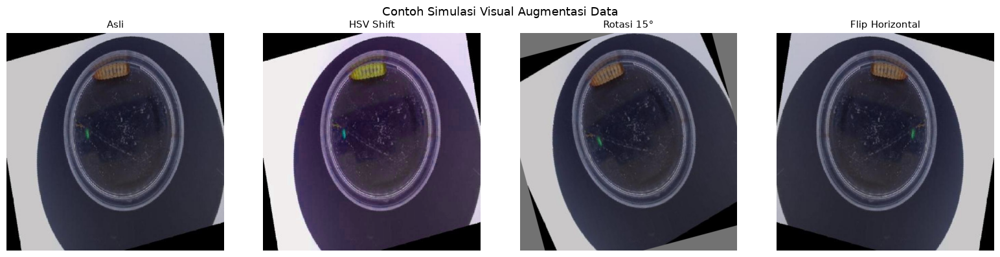

In [11]:
def demo_hsv_shift(image, hue_shift=15, sat_scale=1.4, val_scale=1.2):
    """Simulasi augmentasi HSV untuk ilustrasi (bukan bagian dari pipeline training)."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + hue_shift) % 180
    hsv[..., 1] = np.clip(hsv[..., 1] * sat_scale, 0, 255)
    hsv[..., 2] = np.clip(hsv[..., 2] * val_scale, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

def demo_rotate(image, angle=15):
    h, w = image.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
    return cv2.warpAffine(image, M, (w, h), borderValue=(114, 114, 114))

sample_img_path = random.choice(list(paths["train"]["images"].glob("*.*")))
img = cv2.imread(str(sample_img_path))

variasi = {
    "Asli": img,
    "HSV Shift": demo_hsv_shift(img),
    "Rotasi 15°": demo_rotate(img, 15),
    "Flip Horizontal": cv2.flip(img, 1),
}

fig, axes = plt.subplots(1, len(variasi), figsize=(16, 4))
for ax, (judul, im) in zip(axes, variasi.items()):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(judul, fontsize=11)
    ax.axis("off")
plt.suptitle("Contoh Simulasi Visual Augmentasi Data", fontsize=13)
plt.tight_layout()
plt.savefig("outputs/demo_augmentasi.png", dpi=150, bbox_inches="tight")
plt.show()


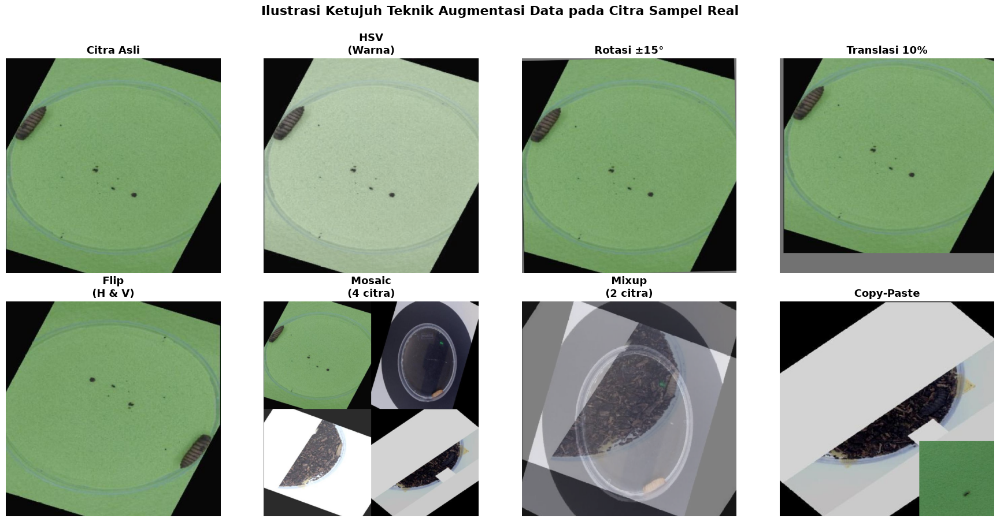

Citra yang dipakai sebagai sampel:
  1. rotate-output158_png.rf.964be3e0d62959ec4d3c09521c1a9958.jpg
  2. rotate-output111_png.rf.9d7cd8be6d3d6bc3af76830342b49dd2.jpg
  3. rotate-output244_png.rf.3695777a4710cc62a77c431f5b10710c.jpg
  4. rotate-output228_png.rf.570c841305dd5adfae4028b6f9694db8.jpg
  5. rotate-output216_png.rf.c40e49e531af45a80fabb66d560008b2.jpg


In [12]:
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt

random.seed(42)

# ============================================================
# Ambil beberapa citra sampel real dari dataset
# ============================================================
semua_gambar = list(paths["train"]["images"].glob("*.*"))
sampel_paths = random.sample(semua_gambar, 5)
sampel_imgs = [cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB) for p in sampel_paths]
img = sampel_imgs[0]  # citra utama untuk augmentasi tunggal

# ============================================================
# Fungsi masing-masing augmentasi
# ============================================================
def augment_hsv(image, hgain=0.015, sgain=0.7, vgain=0.4):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + random.uniform(-hgain, hgain) * 180) % 180
    hsv[..., 1] = np.clip(hsv[..., 1] * (1 + random.uniform(-sgain, sgain)), 0, 255)
    hsv[..., 2] = np.clip(hsv[..., 2] * (1 + random.uniform(-vgain, vgain)), 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

def augment_rotate(image, degrees=15):
    h, w = image.shape[:2]
    angle = random.uniform(-degrees, degrees)
    M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
    return cv2.warpAffine(image, M, (w, h), borderValue=(114, 114, 114))

def augment_translate(image, translate=0.1):
    h, w = image.shape[:2]
    tx = random.uniform(-translate, translate) * w
    ty = random.uniform(-translate, translate) * h
    M = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(image, M, (w, h), borderValue=(114, 114, 114))

def augment_flip(image, arah="horizontal"):
    return cv2.flip(image, 1 if arah == "horizontal" else 0)

def augment_mosaic(images, size=640):
    """Gabungkan 4 citra jadi 1 kanvas 2x2."""
    half = size // 2
    canvas = np.full((size, size, 3), 114, dtype=np.uint8)
    posisi = [(0, 0), (0, half), (half, 0), (half, half)]
    for (y, x), im in zip(posisi, images[:4]):
        resized = cv2.resize(im, (half, half))
        canvas[y:y+half, x:x+half] = resized
    return canvas

def augment_mixup(img1, img2, alpha=0.5):
    """Interpolasi linear dua citra (lambda tetap 0.5 untuk ilustrasi)."""
    img1_r = cv2.resize(img1, (img2.shape[1], img2.shape[0]))
    return cv2.addWeighted(img1_r, alpha, img2, 1 - alpha, 0)

def augment_copy_paste(base_img, source_img, patch_ratio=0.35):
    """Salin patch tengah dari source_img, tempel ke pojok base_img."""
    h, w = base_img.shape[:2]
    ph, pw = int(h * patch_ratio), int(w * patch_ratio)
    sh, sw = source_img.shape[:2]
    patch = cv2.resize(source_img[sh//4:sh//4+sh//2, sw//4:sw//4+sw//2], (pw, ph))
    hasil = base_img.copy()
    hasil[h-ph:h, w-pw:w] = patch
    return hasil

# ============================================================
# Susun ketujuh hasil augmentasi
# ============================================================
hasil_augmentasi = {
    "Citra Asli": img,
    "HSV\n(Warna)": augment_hsv(img.copy()),
    "Rotasi ±15°": augment_rotate(img.copy()),
    "Translasi 10%": augment_translate(img.copy()),
    "Flip\n(H & V)": augment_flip(augment_flip(img.copy(), "horizontal"), "vertical"),
    "Mosaic\n(4 citra)": augment_mosaic(sampel_imgs),
    "Mixup\n(2 citra)": augment_mixup(sampel_imgs[1], sampel_imgs[2]),
    "Copy-Paste": augment_copy_paste(sampel_imgs[3], sampel_imgs[4]),
}

# ============================================================
# Visualisasi: grid 2 baris x 4 kolom
# ============================================================
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for ax, (judul, gambar) in zip(axes, hasil_augmentasi.items()):
    ax.imshow(gambar)
    ax.set_title(judul, fontsize=13, fontweight="bold")
    ax.axis("off")

plt.suptitle("Ilustrasi Ketujuh Teknik Augmentasi Data pada Citra Sampel Real",
             fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout()
plt.savefig("outputs/ilustrasi_7_augmentasi.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("Citra yang dipakai sebagai sampel:")
for i, p in enumerate(sampel_paths):
    print(f"  {i+1}. {p.name}")

---
## 4. Ekstraksi Fitur

### 4.1 Arsitektur YOLOv11 (Ekstraksi Fitur oleh Backbone) — Penjelasan Lengkap Tiap Komponen

YOLOv11 (You Only Look Once versi 11, dikembangkan oleh Ultralytics) adalah model deteksi objek **single-stage** (satu tahap), artinya lokasi bounding box dan klasifikasi kelas diprediksi dalam satu kali forward pass jaringan, tanpa tahap terpisah seperti pada model two-stage (contoh: Faster R-CNN).

Arsitektur YOLOv11 terdiri dari **tiga bagian besar**: **Backbone**, **Neck**, dan **Head**. Berikut penjelasan detail tiap komponen penyusunnya, sesuai urutan proses data dari input hingga output.

### 4.1.1 Backbone — Ekstraksi Fitur

Backbone bertugas mengekstrak fitur visual dari citra input secara bertahap, dari fitur tingkat rendah (tepi, tekstur) di layer awal, hingga fitur tingkat tinggi (bentuk, pola objek) di layer akhir. Backbone YOLOv11 tersusun dari modul-modul berikut:

**a. Conv (Convolutional Block)**
Blok dasar berisi operasi Convolution + Batch Normalization + aktivasi SiLU (Sigmoid Linear Unit). Berfungsi mengekstrak fitur sekaligus melakukan downsampling (mengecilkan resolusi spasial, memperbesar jumlah channel) melalui stride 2.

$$\text{SiLU}(x) = x \cdot \sigma(x) = \frac{x}{1+e^{-x}}$$

**b. C3k2 (CSP Bottleneck dengan 2 Convolution, varian k3)**
C3k2 adalah pengembangan dari C2f (dipakai di YOLOv8) yang dipakai di YOLOv11. Modul ini menerapkan konsep **CSP (Cross Stage Partial)**: fitur input dibagi dua jalur, satu jalur diproses melalui serangkaian *bottleneck block* (residual), satu jalur lain diteruskan langsung (*shortcut*), lalu keduanya digabung (*concat*). Tujuannya mengurangi duplikasi komputasi gradien sambil tetap mempertahankan aliran informasi yang kaya, sehingga model lebih ringan tanpa kehilangan akurasi.

**c. SPPF (Spatial Pyramid Pooling - Fast)**
Modul ini menerapkan *max pooling* dengan beberapa ukuran kernel berbeda secara berurutan (bukan paralel seperti SPP versi awal, sehingga lebih cepat), untuk menangkap konteks spasial dari berbagai skala reseptif sekaligus, dalam satu blok fitur akhir backbone. Ini penting agar model bisa mendeteksi larva dengan ukuran/skala yang sangat bervariasi dalam satu frame foto.

**d. C2PSA (Cross Stage Partial with Parallel Spatial Attention)**
Modul baru khas YOLOv11 (tidak ada di YOLOv8) yang menambahkan mekanisme **attention** spasial ke fitur backbone. Attention memungkinkan model memberi "bobot perhatian" lebih besar pada area citra yang relevan (misal, badan larva) dan mengabaikan area kurang relevan (misal, background tanah/plastik), meningkatkan akurasi deteksi terutama pada objek kecil atau objek dengan latar belakang ramai — sangat relevan untuk dataset kita yang memiliki variasi background tinggi.

### 4.1.2 Neck — Penggabungan Fitur Multi-Skala

Neck menggabungkan fitur dari berbagai level resolusi backbone (fitur resolusi tinggi kaya detail tapi kurang konteks semantik, fitur resolusi rendah sebaliknya) agar model bisa mendeteksi objek pada berbagai ukuran secara efektif. YOLOv11 memakai arsitektur **PANet (Path Aggregation Network)**, gabungan dari:

- **FPN (Feature Pyramid Network)** — alur *top-down*: fitur resolusi rendah (semantik kuat) di-*upsample* dan digabung dengan fitur resolusi lebih tinggi secara bertahap.
- **PAN (Path Aggregation)** — alur tambahan *bottom-up*: fitur hasil FPN diproses kembali dari resolusi tinggi ke rendah, memperkuat aliran informasi lokasi (detail spasial) ke level fitur yang lebih dalam.

Kombinasi dua alur ini (top-down + bottom-up) membuat setiap level fitur akhir memiliki kombinasi informasi semantik **dan** detail lokasi spasial yang seimbang, sehingga deteksi objek besar maupun kecil (larva dalam foto close-up vs foto zoom-out) sama-sama akurat.

### 4.1.3 Head — Prediksi Akhir

Head menghasilkan prediksi akhir dari fitur yang sudah diproses Neck, pada tiga skala resolusi berbeda (untuk objek kecil, sedang, besar). YOLOv11 memakai pendekatan **anchor-free** (berbeda dari YOLO versi lama yang anchor-based) dan **decoupled head** (kepala klasifikasi dan regresi bounding box dipisah menjadi cabang berbeda, bukan digabung dalam satu convolution seperti YOLO versi sangat lama):

- **Cabang Klasifikasi** — memprediksi skor kepercayaan (*confidence score*) untuk tiap kelas (4 kelas fase pertumbuhan pada proyek ini) di setiap titik grid.
- **Cabang Regresi Bounding Box (DFL — Distribution Focal Loss)** — alih-alih memprediksi koordinat bounding box langsung sebagai satu angka, YOLOv11 memprediksi **distribusi probabilitas** kemungkinan jarak tepi kotak dari titik pusat, lalu jarak final dihitung sebagai ekspektasi (weighted sum) dari distribusi tersebut. Pendekatan ini terbukti lebih stabil dan akurat dibanding regresi langsung, terutama untuk objek dengan batas yang ambigu (larva dengan bentuk memanjang tidak beraturan).

Karena anchor-free, YOLOv11 tidak memerlukan anchor box yang telah ditentukan sebelumnya (predefined), melainkan langsung memprediksi jarak dari tiap titik grid ke keempat sisi bounding box.

### 4.1.4 Fungsi Loss (Fungsi Kerugian)

Total loss YOLOv11 merupakan penjumlahan berbobot dari tiga komponen:

$$\mathcal{L}_{total} = \lambda_{box}\mathcal{L}_{box} + \lambda_{cls}\mathcal{L}_{cls} + \lambda_{dfl}\mathcal{L}_{dfl}$$

- **$\mathcal{L}_{box}$ (CIoU Loss)** — mengukur seberapa jauh bounding box prediksi dari ground truth, mempertimbangkan tumpang tindih (IoU), jarak titik pusat, dan rasio aspek.
- **$\mathcal{L}_{cls}$ (Binary Cross-Entropy)** — mengukur kesalahan klasifikasi kelas per titik grid.
- **$\mathcal{L}_{dfl}$ (Distribution Focal Loss)** — melatih distribusi probabilitas jarak tepi kotak (dijelaskan pada bagian Head di atas) agar mendekati posisi ground truth sebenarnya.

Bobot default yang dipakai Ultralytics: `box=7.5`, `cls=0.5`, `dfl=1.5` — nilai ini yang juga kita pakai pada training (tidak diubah dari default, karena hasil eksperimen tuning menunjukkan nilai default sudah optimal untuk dataset ini).

### 4.1.5 Ringkasan Alur Data dalam Arsitektur

```
Input (640x640x3)
      |
  BACKBONE   : Conv -> C3k2 -> Conv -> C3k2 -> Conv -> C3k2 -> Conv -> C3k2 -> SPPF -> C2PSA
      |            (fitur diekstrak bertahap, resolusi mengecil, channel membesar)
      v
   NECK      : FPN (top-down upsample + concat) -> PAN (bottom-up downsample + concat)
      |            (fitur multi-skala digabung: P3/8, P4/16, P5/32)
      v
   HEAD      : Cabang Klasifikasi (per kelas) + Cabang Regresi DFL (bounding box)
      |            pada tiga skala resolusi berbeda
      v
Output: [class_id, confidence, x, y, w, h] untuk tiap kandidat deteksi
      |
     NMS     : Non-Maximum Suppression menghapus deteksi duplikat/tumpang tindih
```


In [13]:
from ultralytics import YOLO

# Memuat arsitektur YOLOv11s (varian small) - cetak ringkasan struktur layer
model = YOLO("yolo11s.pt")
print(model.model)  # menampilkan seluruh susunan layer: Conv, C3k2, SPPF, C2PSA, dst.


DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C3k2(
      (cv1): Conv(
        (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
 

In [14]:
# Cetak jumlah parameter total & per bagian (Backbone/Neck/Head tergabung sebagai model.model)
total_params = sum(p.numel() for p in model.model.parameters())
trainable_params = sum(p.numel() for p in model.model.parameters() if p.requires_grad)
print(f"Total parameter model YOLOv11s: {total_params:,}")
print(f"Parameter yang dapat dilatih: {trainable_params:,}")


Total parameter model YOLOv11s: 9,458,752
Parameter yang dapat dilatih: 0


### 4.2 Modul Ekstraksi Ciri Visual (Warna & Tekstur) — Penjelasan Lengkap

Setiap larva yang terdeteksi YOLOv11 diproses lebih lanjut oleh **dua algoritma pengolahan citra klasik** (bukan deep learning) untuk mengekstrak ciri visual tambahan: **warna dominan** dan **tekstur permukaan**. Berikut penjelasan lengkap keduanya, dengan format penjelasan yang sama detailnya seperti arsitektur YOLOv11 di atas.

### 4.2.1 Ekstraksi Warna Dominan — Algoritma K-Means Clustering

**K-Means** adalah algoritma *unsupervised clustering* yang mengelompokkan sekumpulan titik data (dalam kasus ini, nilai RGB tiap piksel) ke dalam **k kelompok (cluster)** berdasarkan kemiripan nilai, sehingga titik-titik dalam satu cluster saling berdekatan, sementara cluster berbeda saling berjauhan.

**Tahapan algoritma (Lloyd's Algorithm):**

1. **Resize & Ekstraksi Piksel** — citra crop larva di-resize ke 50x50 piksel (untuk mempercepat komputasi), lalu setiap piksel diambil sebagai titik data 3 dimensi (R, G, B).

2. **Inisialisasi Centroid** — pilih `k=3` titik data secara acak sebagai pusat cluster awal (centroid).

3. **Assignment Step** — setiap piksel di-assign ke centroid terdekat, dihitung menggunakan jarak Euclidean kuadrat:

$$d(p, c) = (p_R - c_R)^2 + (p_G - c_G)^2 + (p_B - c_B)^2$$

4. **Update Step** — posisi tiap centroid diperbarui menjadi rata-rata (mean) seluruh piksel yang ter-assign padanya:

$$c_k = \frac{1}{|S_k|}\sum_{p \in S_k} p$$

dengan $S_k$ adalah himpunan piksel yang menjadi anggota cluster $k$.

5. **Iterasi** — langkah 3-4 diulang hingga posisi centroid stabil (pergeseran < epsilon 0,5) atau mencapai batas maksimum 20 iterasi.

6. **Pemilihan Warna Dominan** — cluster dengan **jumlah anggota piksel terbanyak** dipilih sebagai warna dominan larva tersebut.

7. **Klasifikasi Nama Warna** — nilai RGB dominan diklasifikasikan ke salah satu dari 6 kategori nama warna (hitam pekat, oranye kecoklatan, krem pucat, coklat kemerahan, pucat/terang, coklat gelap) berdasarkan kombinasi nilai brightness dan rasio R/G/B.

**Kenapa K-Means, bukan sekadar rata-rata warna?** Rata-rata warna seluruh piksel bisa menyesatkan jika ada campuran warna larva dan sisa background yang belum sepenuhnya ter-crop. K-Means memisahkan piksel jadi kelompok-kelompok warna berbeda, sehingga warna "dominan" yang diambil benar-benar mencerminkan warna terbanyak/paling representatif, bukan warna "rata-rata" yang bisa jadi tidak mewakili warna manapun secara nyata.

### 4.2.2 Ekstraksi Tekstur Permukaan — Algoritma Laplacian Variance

**Operator Laplacian** adalah operator turunan kedua yang mengukur tingkat perubahan intensitas piksel secara lokal — area dengan tekstur kasar/bergaris memiliki variasi intensitas piksel yang tinggi antar piksel bertetangga, sementara area halus memiliki variasi yang rendah.

**Tahapan algoritma:**

1. **Konversi ke Grayscale** — citra crop larva (RGB) diubah menjadi grayscale, karena analisis tekstur berbasis intensitas, bukan warna.

2. **Konvolusi Kernel Laplacian** — setiap piksel dihitung nilai Laplacian-nya menggunakan kernel konvolusi 4-tetangga:

$$L(x,y) = I(x-1,y) + I(x+1,y) + I(x,y-1) + I(x,y+1) - 4 \cdot I(x,y)$$

dengan $I(x,y)$ adalah nilai intensitas grayscale pada koordinat $(x,y)$. Nilai Laplacian besar (baik positif maupun negatif) menunjukkan perubahan intensitas tajam (tepi/garis), nilai mendekati nol menunjukkan area homogen/halus.

3. **Perhitungan Variansi** — seluruh nilai Laplacian pada citra dihitung variansinya:

$$\sigma^2_L = \frac{1}{n}\sum_{i=1}^{n}(L_i - \mu_L)^2$$

dengan $n$ jumlah piksel, $L_i$ nilai Laplacian piksel ke-$i$, dan $\mu_L$ rata-rata nilai Laplacian. **Semakin tinggi variansi, semakin kasar/bertekstur permukaan objek** — karena variansi tinggi berarti banyak piksel dengan nilai Laplacian ekstrem (banyak tepi/garis), bukan area homogen.

4. **Klasifikasi Kategori Tekstur** — berdasarkan ambang batas empiris:

| Variansi Laplacian | Kategori |
|---|---|
| > 500 | Kasar/berkerak |
| 150 - 500 | Bergaris jelas (segmen tubuh terlihat) |
| < 150 | Halus |

Ambang ini konsisten dengan pengamatan bahwa larva fase Pupa (permukaan kapsul berkerak) punya variansi Laplacian tertinggi, sedangkan Larva Muda (permukaan lebih halus) punya variansi terendah.

Secara rinci, tekstur pada larva muda terlihat relatif halus sehingga menghasilkan respons Laplacian yang lebih rendah. Sebaliknya, pada fase prepupa dan pupa terlihat pola tekstur yang lebih jelas akibat permukaan tubuh yang lebih kasar. Perbedaan tersebut menunjukkan bahwa fitur tekstur dapat digunakan sebagai informasi tambahan dalam membedakan fase pertumbuhan larva BSF.


In [15]:
def get_dominant_color(crop_img, k=3, max_iter=20, epsilon=0.5):
    """
    Ekstraksi warna dominan menggunakan algoritma K-Means Clustering.
    Tahapan: resize -> kumpulkan piksel -> clustering -> pilih cluster terbesar.
    """
    img_small = cv2.resize(crop_img, (50, 50))
    pixels = img_small.reshape(-1, 3).astype(np.float32)

    # Kriteria berhenti: max_iter iterasi ATAU pergeseran centroid < epsilon
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, max_iter, epsilon)
    _, labels, centers = cv2.kmeans(pixels, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    # Pilih cluster dengan jumlah anggota piksel terbanyak
    counts = np.bincount(labels.flatten())
    dominant_bgr = centers[np.argmax(counts)]
    b, g, r = dominant_bgr
    return int(r), int(g), int(b)


def classify_color_name(r, g, b):
    """Klasifikasi nilai RGB dominan ke salah satu dari 6 kategori nama warna."""
    brightness = (r + g + b) / 3
    if brightness < 60:
        return "hitam pekat"
    elif r > 150 and g > 100 and b < 100:
        return "oranye kecoklatan"
    elif r > 180 and g > 150 and b > 100:
        return "krem pucat"
    elif r > 100 and g > 70 and b < 90:
        return "coklat kemerahan"
    elif brightness > 150:
        return "pucat/terang"
    else:
        return "coklat gelap"


def analyze_texture(crop_img):
    """
    Ekstraksi tekstur permukaan menggunakan variansi filter Laplacian.
    Tahapan: grayscale -> konvolusi Laplacian -> hitung variansi -> klasifikasi kategori.
    """
    gray = cv2.cvtColor(crop_img, cv2.COLOR_BGR2GRAY)
    laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()

    # Tambahan: edge density via Canny, sebagai info pendukung (tidak dipakai untuk kategori utama)
    edges = cv2.Canny(gray, 50, 150)
    edge_density = np.sum(edges > 0) / edges.size

    if laplacian_var > 500:
        texture_label = "kasar/berkerak"
    elif laplacian_var > 150:
        texture_label = "bergaris jelas (segmen tubuh terlihat)"
    else:
        texture_label = "halus"

    return {
        "laplacian_var": laplacian_var,
        "edge_density": edge_density,
        "texture_label": texture_label,
    }


In [16]:
import cv2
from collections import Counter
from pathlib import Path

# ============================================================
# Cek ukuran (width x height) SELURUH citra di setiap split
# ============================================================
ukuran_per_split = {}

for split in SPLITS:
    images_folder = paths[split]["images"]
    ukuran_counter = Counter()
    
    for img_path in images_folder.glob("*.*"):
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        ukuran_counter[(w, h)] += 1
    
    ukuran_per_split[split] = ukuran_counter
    
    print(f"\n=== Split: {split} (total {sum(ukuran_counter.values())} citra) ===")
    # Urutkan dari yang paling banyak
    for (w, h), jumlah in ukuran_counter.most_common(10):
        persen = jumlah / sum(ukuran_counter.values()) * 100
        print(f"  {w}x{h} piksel : {jumlah} citra ({persen:.1f}%)")
    if len(ukuran_counter) > 10:
        print(f"  ... dan {len(ukuran_counter) - 10} ukuran lainnya")

# ============================================================
# Ringkasan keseluruhan
# ============================================================
semua_ukuran = Counter()
for counter in ukuran_per_split.values():
    semua_ukuran.update(counter)

print("\n" + "=" * 60)
print(f"RINGKASAN TOTAL: {len(semua_ukuran)} ukuran unik ditemukan")
print("=" * 60)
for (w, h), jumlah in semua_ukuran.most_common(10):
    persen = jumlah / sum(semua_ukuran.values()) * 100
    print(f"  {w}x{h} piksel : {jumlah} citra ({persen:.1f}%)")

apakah_semua_640 = len(semua_ukuran) == 1 and (640, 640) in semua_ukuran
print(f"\nApakah SEMUA citra 640x640? {'YA' if apakah_semua_640 else 'TIDAK'}")


=== Split: train (total 20049 citra) ===
  640x640 piksel : 20049 citra (100.0%)

=== Split: valid (total 1347 citra) ===
  640x640 piksel : 1347 citra (100.0%)

=== Split: test (total 578 citra) ===
  640x640 piksel : 578 citra (100.0%)

RINGKASAN TOTAL: 1 ukuran unik ditemukan
  640x640 piksel : 21974 citra (100.0%)

Apakah SEMUA citra 640x640? YA


In [17]:
import cv2
import random

# Ambil 1 citra sampel dari dataset
sample_img_path = random.choice(list(paths["train"]["images"].glob("*.*")))
img = cv2.imread(str(sample_img_path))

print(f"Citra sampel: {sample_img_path.name}")
print(f"Ukuran: {img.shape[1]}x{img.shape[0]} piksel\n")

# Ambil 5 piksel pertama (baris pertama, kolom 0-4) sebagai contoh nyata
print("Contoh Normalisasi pada 5 Piksel Real:")
print(f"{'Piksel ke-':<12}{'Nilai Asli (B,G,R)':<20}{'Setelah Normalisasi'}")
for i in range(5):
    b, g, r = img[0, i]
    b_norm, g_norm, r_norm = b/255, g/255, r/255
    print(f"{i+1:<12}({b},{g},{r}){'':<10}({b_norm:.3f}, {g_norm:.3f}, {r_norm:.3f})")

Citra sampel: rotate-output148_png.rf.b25bd18c9b0484484f1181dd59347318.jpg
Ukuran: 640x640 piksel

Contoh Normalisasi pada 5 Piksel Real:
Piksel ke-  Nilai Asli (B,G,R)  Setelah Normalisasi
1           (0,0,0)          (0.000, 0.000, 0.000)
2           (0,0,0)          (0.000, 0.000, 0.000)
3           (0,0,0)          (0.000, 0.000, 0.000)
4           (0,0,0)          (0.000, 0.000, 0.000)
5           (0,0,0)          (0.000, 0.000, 0.000)


### 4.3 Visualisasi Hasil Peta Laplacian

Sel berikut mendemonstrasikan perbandingan secara visual antara crop larva asli dengan hasil peta variansi Laplacian untuk membedakan tekstur permukaan tubuh larva.


In [18]:
def visualize_visual_traits_process(crop_img):
    """Visualisasi perbandingan gambar crop larva asli dan peta Laplacian (tekstur)."""
    texture_info = analyze_texture(crop_img)

    gray = cv2.cvtColor(crop_img, cv2.COLOR_BGR2GRAY)
    laplacian_map = cv2.Laplacian(gray, cv2.CV_64F)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    # Tampilkan Gambar Crop Larva Asli
    axes[0].imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Crop Larva Asli")
    axes[0].axis("off")

    # Tampilkan Peta Laplacian
    im = axes[1].imshow(laplacian_map, cmap="gray")
    axes[1].set_title(f"Peta Laplacian (Tekstur)\n{texture_info['texture_label']}\n"
                       f"variansi={texture_info['laplacian_var']:.1f}")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

# Ambil contoh crop larva dari hasil deteksi untuk ditampilkan
sample_img_path = random.choice(list(paths["test"]["images"].glob("*.*")))
results = model.predict(source=str(sample_img_path), conf=0.25, verbose=False)
result = results[0]
if len(result.boxes) > 0:
    box = result.boxes[0]
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    crop = result.orig_img[max(y1,0):y2, max(x1,0):x2]
    visualize_visual_traits_process(crop)
else:
    print("Tidak ada larva terdeteksi pada gambar sampel ini.")


Tidak ada larva terdeteksi pada gambar sampel ini.


In [19]:
import torch

def detect_larvae(image_path, conf_threshold=0.25):
    with torch.no_grad():
        results = model.predict(source=str(image_path), conf=conf_threshold, verbose=False)
    result = results[0]
    detections = []
    for box in result.boxes:
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        detections.append({
            "class_id": cls_id,
            "class_name": CLASS_NAMES[cls_id],
            "confidence": conf,
            "bbox": (int(x1), int(y1), int(x2), int(y2)),
        })
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return detections, result.orig_img

In [20]:
TRAINED_RUN_DIR = PROJECT_ROOT / "runs" / "detect" / "runs" / "yolov11s_bsf_larva-7"
BEST_MODEL_SRC = TRAINED_RUN_DIR / "weights" / "best.pt"
BEST_MODEL_DST = PROJECT_ROOT / "models" / "yolov11_bsf" / "best.pt"

if BEST_MODEL_SRC.exists() and not BEST_MODEL_DST.exists():
    BEST_MODEL_DST.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(str(BEST_MODEL_SRC), str(BEST_MODEL_DST))
    print(f"Model disalin ke: {BEST_MODEL_DST}")

model = YOLO(str(BEST_MODEL_DST)) if BEST_MODEL_DST.exists() else YOLO(str(BEST_MODEL_SRC))

print("Kelas model:", model.names)

Kelas model: {0: 'Larva Muda', 1: 'Larva Dewasa', 2: 'Prepupa', 3: 'Pupa'}


Tabel 3.7 Rangkuman Hasil Ekstraksi Tekstur Permukaan dan Variansi Laplacian
                                                                         Nama Citra      Ukuran Crop Jumlah Piksel (n) Jumlah Laplacian (ΣLi) Rata-rata Laplacian (μL) Total Kuadrat Selisih Laplacian Variance (σL²) Kategori Tekstur
Larva Muda    nvcamtest_11764_s00_00001_jpg.rf.04aab7a72ef2df4d089f4fc0b2a04f58.jpg   53 x 28 piksel              1484                 -107.0                  -0.0721             354077.29                    238.6   Bergaris Jelas
Larva Dewasa  nvcamtest_10067_s00_00051_jpg.rf.6a436334a7e8742ca82279662bead841.jpg  106 x 97 piksel             10282                 -436.0                  -0.0424             439259.51                    42.72            Halus
Prepupa       nvcamtest_10672_s00_00049_jpg.rf.18a7535e4fd56320e057c2d6cebe53f0.jpg  59 x 121 piksel              7139                 -869.0                  -0.1217             549053.22                    76.91            Halus

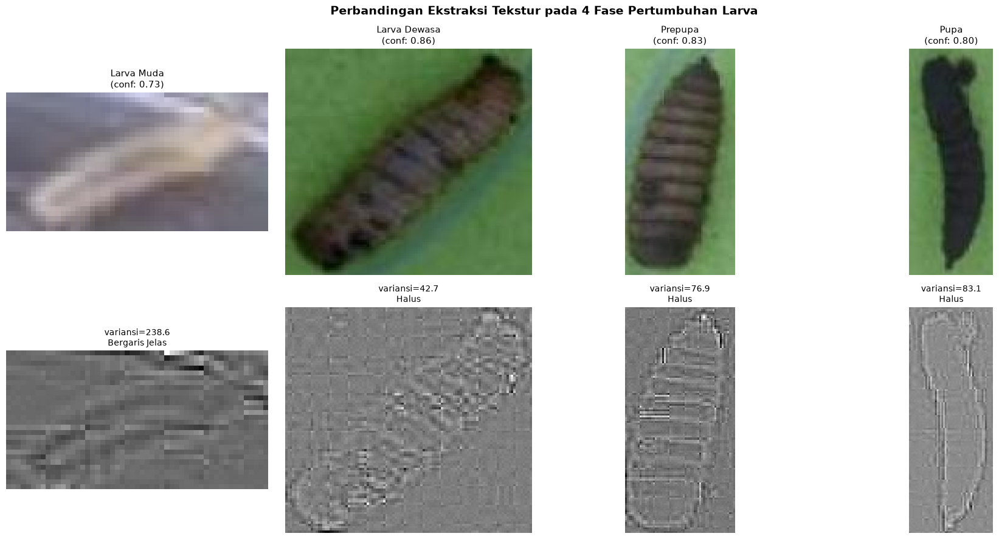


Tabel 3.13 Hasil Ekstraksi Tekstur Permukaan pada Empat Fase
Fase Pertumbuhan  Laplacian Variance Kategori Tekstur
      Larva Muda              238.60   Bergaris Jelas
    Larva Dewasa               42.72            Halus
         Prepupa               76.91            Halus
            Pupa               83.13            Halus


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

prefix_per_fase = {
    "Larva Muda":   "nvcamtest_11764",
    "Larva Dewasa": "nvcamtest_10067",
    "Prepupa":      "nvcamtest_10672",
    "Pupa":         "nvcamtest_11296",
}

file_per_fase = {}
semua_test_images = list(paths["test"]["images"].glob("*.*"))
for fase, prefix in prefix_per_fase.items():
    kandidat = [p for p in semua_test_images if p.name.startswith(prefix)]
    if kandidat:
        file_per_fase[fase] = kandidat[0]

# ============================================================
# PERBAIKAN: pakai BORDER_REFLECT_101 
# ============================================================
def hitung_laplacian_manual(gray_img):
    gray_f = gray_img.astype(np.float64)
    kernel = np.array([[0, 1, 0],
                        [1, -4, 1],
                        [0, 1, 0]], dtype=np.float64)
    L = cv2.filter2D(gray_f, ddepth=-1, kernel=kernel, borderType=cv2.BORDER_REFLECT_101)
    return L

def klasifikasi_tekstur_lama(variansi):
    if variansi > 500:
        return "Kasar/Berkerak"
    elif variansi > 150:
        return "Bergaris Jelas"
    else:
        return "Halus"

hasil_lengkap = {}
for fase, img_path in file_per_fase.items():
    detections, orig_img = detect_larvae(img_path, conf_threshold=0.25)
    if len(detections) == 0:
        continue
    det = detections[0]
    x1, y1, x2, y2 = det["bbox"]
    crop_img = orig_img[y1:y2, x1:x2]

    gray = cv2.cvtColor(crop_img, cv2.COLOR_BGR2GRAY)
    L = hitung_laplacian_manual(gray)

    n = L.size
    sum_L = L.sum()
    mean_L = sum_L / n
    total_kuadrat_selisih = ((L - mean_L) ** 2).sum()
    variansi = total_kuadrat_selisih / n
    kategori = klasifikasi_tekstur_lama(variansi)

    hasil_lengkap[fase] = {
        "file": img_path.name, "confidence": det["confidence"],
        "crop": crop_img, "gray": gray, "laplacian_map": L,
        "ukuran": f"{crop_img.shape[1]} x {crop_img.shape[0]} piksel",
        "n": n, "sum_L": sum_L, "mean_L": mean_L,
        "total_kuadrat_selisih": total_kuadrat_selisih,
        "variansi": variansi, "kategori": kategori,
    }

print("=" * 90)
print("Tabel 3.7 Rangkuman Hasil Ekstraksi Tekstur Permukaan dan Variansi Laplacian")
print("=" * 90)
rangkuman = pd.DataFrame({
    fase: {
        "Nama Citra": h["file"], "Ukuran Crop": h["ukuran"], "Jumlah Piksel (n)": h["n"],
        "Jumlah Laplacian (ΣLi)": round(h["sum_L"], 2),
        "Rata-rata Laplacian (μL)": round(h["mean_L"], 4),
        "Total Kuadrat Selisih": round(h["total_kuadrat_selisih"], 2),
        "Laplacian Variance (σL²)": round(h["variansi"], 2),
        "Kategori Tekstur": h["kategori"],
    } for fase, h in hasil_lengkap.items()
}).T
print(rangkuman.to_string())

for fase, h in hasil_lengkap.items():
    print(f"\n--- Rincian Perhitungan Laplacian pada {fase} (5 piksel pertama) ---")
    gray_flat = h["gray"].flatten()
    L_flat = h["laplacian_map"].flatten()
    selisih = L_flat - h["mean_L"]
    tabel_rincian = pd.DataFrame({
        "Piksel ke-i": range(1, 6), "Grayscale (Ii)": gray_flat[:5],
        "Laplacian (Li)": np.round(L_flat[:5], 4),
        "Selisih (Li-μL)": np.round(selisih[:5], 4),
        "Kuadrat Selisih": np.round(selisih[:5] ** 2, 4),
    })
    print(tabel_rincian.to_string(index=False))
    print(f"Total ({h['n']} piksel) | ΣLi={h['sum_L']:.2f} | Σ(Li-μL)²={h['total_kuadrat_selisih']:.2f}")

urutan_fase = ["Larva Muda", "Larva Dewasa", "Prepupa", "Pupa"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for i, fase in enumerate(urutan_fase):
    if fase not in hasil_lengkap:
        continue
    h = hasil_lengkap[fase]
    axes[0, i].imshow(cv2.cvtColor(h["crop"], cv2.COLOR_BGR2RGB))
    axes[0, i].set_title(f"{fase}\n(conf: {h['confidence']:.2f})", fontsize=11)
    axes[0, i].axis("off")
    axes[1, i].imshow(h["laplacian_map"], cmap="gray")
    axes[1, i].set_title(f"variansi={h['variansi']:.1f}\n{h['kategori']}", fontsize=10)
    axes[1, i].axis("off")
plt.suptitle("Perbandingan Ekstraksi Tekstur pada 4 Fase Pertumbuhan Larva", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/gambar_perbandingan_tekstur_4_fase_final.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("\n" + "=" * 60)
print("Tabel 3.13 Hasil Ekstraksi Tekstur Permukaan pada Empat Fase")
print("=" * 60)
tabel_akhir = pd.DataFrame({
    "Fase Pertumbuhan": list(hasil_lengkap.keys()),
    "Laplacian Variance": [round(h["variansi"], 2) for h in hasil_lengkap.values()],
    "Kategori Tekstur": [h["kategori"] for h in hasil_lengkap.values()],
})
print(tabel_akhir.to_string(index=False))

### 4.4 Contoh Ciri Visual per Fase Pertumbuhan

Sel berikut menjalankan `visualize_visual_traits_process` (fungsi yang sama dari sub bab 4.3, tidak diubah) pada satu contoh larva dari **setiap fase**, untuk mendukung Tabel 3.5 yang membandingkan hasil ekstraksi warna dan tekstur antarfase.

=== Fase: Larva Muda ===


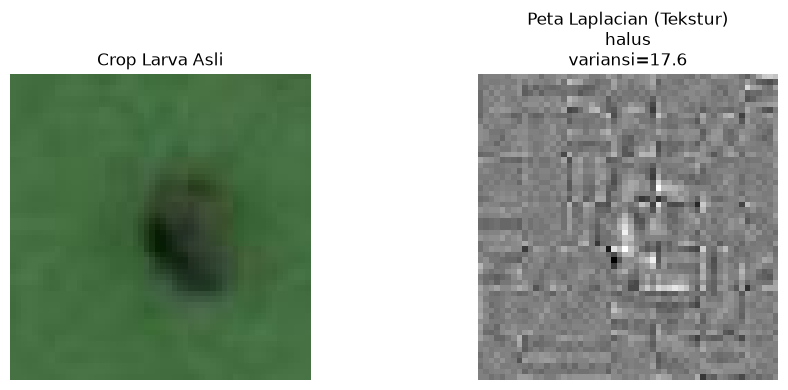

=== Fase: Larva Dewasa ===


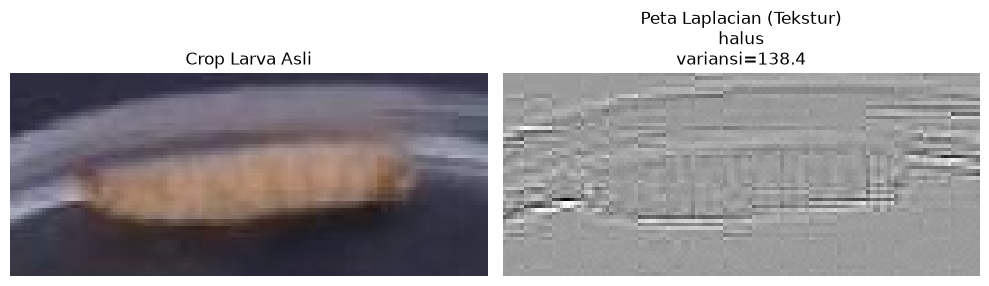

=== Fase: Prepupa ===


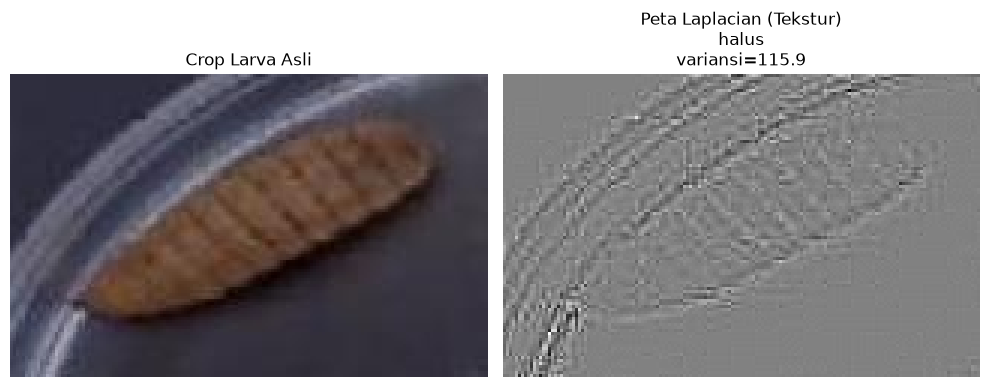

=== Fase: Pupa ===


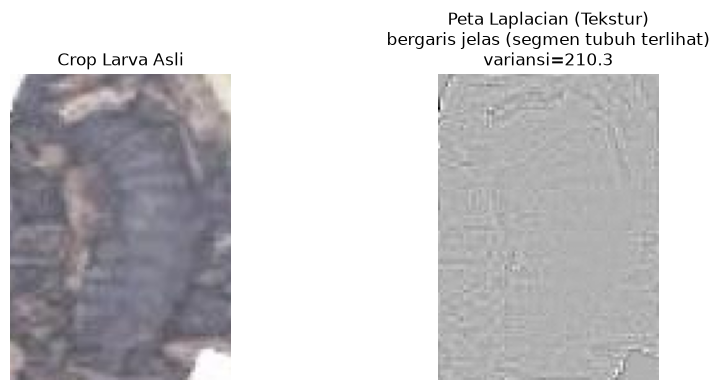

In [22]:
def get_one_crop_per_class(target_class, images_folder, labels_folder, seed=42):
    random.seed(seed)
    label_files = list(Path(labels_folder).glob("*.txt"))
    random.shuffle(label_files)
    for label_file in label_files:
        rows = read_yolo_label(label_file)
        matching = [r for r in rows if int(r[0]) == target_class]
        if not matching:
            continue
        img_path = Path(images_folder) / f"{label_file.stem}.jpg"
        if not img_path.exists():
            img_path = Path(images_folder) / f"{label_file.stem}.png"
        if not img_path.exists():
            continue
        img = cv2.imread(str(img_path))
        h, w = img.shape[:2]
        xc, yc, bw, bh = map(float, matching[0][1:5])
        x1, y1, x2, y2 = int((xc-bw/2)*w), int((yc-bh/2)*h), int((xc+bw/2)*w), int((yc+bh/2)*h)
        pad = 15
        x1c, y1c = max(x1-pad,0), max(y1-pad,0)
        x2c, y2c = min(x2+pad,w), min(y2+pad,h)
        return img[y1c:y2c, x1c:x2c]
    return None

for class_idx, class_name in enumerate(CLASS_NAMES):
    crop = get_one_crop_per_class(class_idx, paths["train"]["images"], paths["train"]["labels"])
    if crop is not None and crop.size > 0:
        print(f"=== Fase: {class_name} ===")
        visualize_visual_traits_process(crop)
    else:
        print(f"Tidak ditemukan contoh untuk fase: {class_name}")


Ditemukan sampel untuk 4 dari 4 fase

=== Larva Muda (rotate-output125_png.rf.7e187592dd2879b608681dd34e0404a9.jpg) ===
RGB dominan: (107, 80, 57) -> coklat kemerahan
Variansi Laplacian: 106.93 -> halus

=== Larva Dewasa (rotate-output163_png.rf.8a1aa9b7c90d82fdb78d912447f0e185.jpg) ===
RGB dominan: (105, 143, 87) -> coklat kemerahan
Variansi Laplacian: 59.42 -> halus

=== Prepupa (rotate-output168_png.rf.d6e0b1511e01fa16eb65df3e23b9884e.jpg) ===
RGB dominan: (104, 141, 95) -> coklat gelap
Variansi Laplacian: 158.21 -> bergaris jelas (segmen tubuh terlihat)

=== Pupa (rotate-output118_png.rf.76e2f795d287628dbce727a7146a3d06.jpg) ===
RGB dominan: (50, 48, 44) -> hitam pekat
Variansi Laplacian: 157.96 -> bergaris jelas (segmen tubuh terlihat)



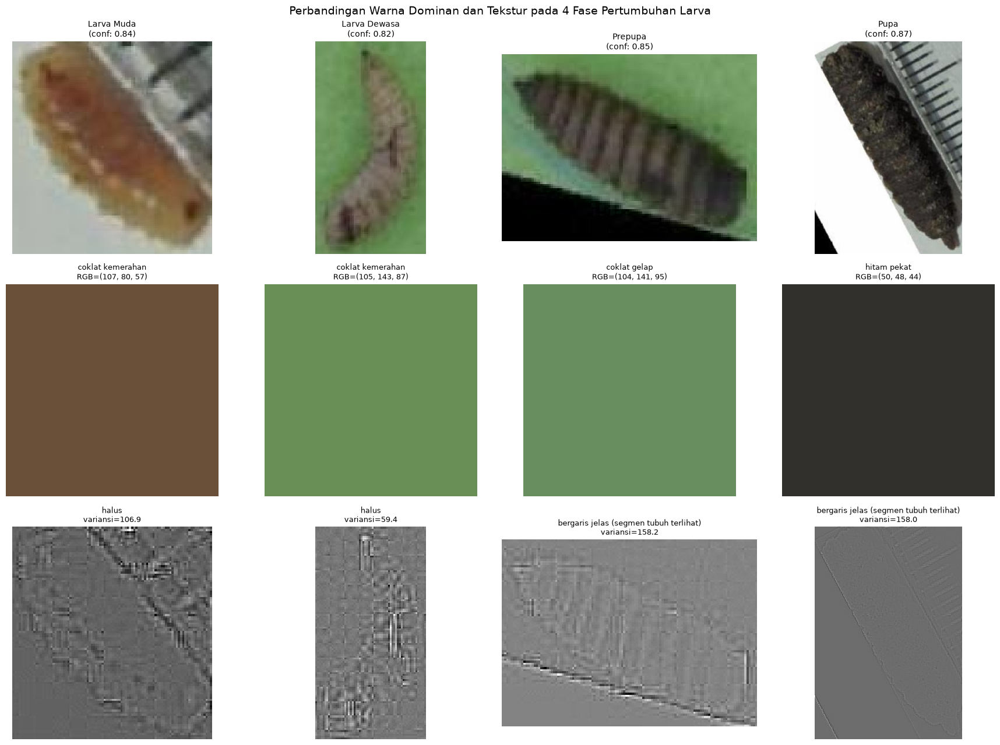

In [23]:
sampel_per_fase = {}
semua_test_images = list(paths["test"]["images"].glob("*.*"))
random.shuffle(semua_test_images)

for img_path in semua_test_images:
    if len(sampel_per_fase) == len(CLASS_NAMES):
        break
    detections, orig_img = detect_larvae(img_path, conf_threshold=0.25)
    for det in detections:
        fase = det["class_name"]
        if fase not in sampel_per_fase:
            x1, y1, x2, y2 = det["bbox"]
            crop_img = orig_img[y1:y2, x1:x2]
            sampel_per_fase[fase] = {"nama_file": img_path.name, "confidence": det["confidence"], "crop": crop_img}

print(f"Ditemukan sampel untuk {len(sampel_per_fase)} dari {len(CLASS_NAMES)} fase\n")

fig, axes = plt.subplots(3, 4, figsize=(18, 13))

for i, fase in enumerate(CLASS_NAMES):
    if fase not in sampel_per_fase:
        continue
    data = sampel_per_fase[fase]
    crop_img = data["crop"]

    rgb_dominan = get_dominant_color(crop_img, k=3)
    nama_warna = classify_color_name(*rgb_dominan)
    hasil_tekstur = analyze_texture(crop_img)

    print(f"=== {fase} ({data['nama_file']}) ===")
    print(f"RGB dominan: {rgb_dominan} -> {nama_warna}")
    print(f"Variansi Laplacian: {hasil_tekstur['laplacian_var']:.2f} -> {hasil_tekstur['texture_label']}\n")

    gray = cv2.cvtColor(crop_img, cv2.COLOR_BGR2GRAY)
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    swatch = np.full((100, 100, 3), rgb_dominan, dtype=np.uint8)

    axes[0, i].imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
    axes[0, i].set_title(f"{fase}\n(conf: {data['confidence']:.2f})", fontsize=10)
    axes[0, i].axis("off")

    axes[1, i].imshow(swatch)
    axes[1, i].set_title(f"{nama_warna}\nRGB={rgb_dominan}", fontsize=9)
    axes[1, i].axis("off")

    axes[2, i].imshow(laplacian, cmap="gray")
    axes[2, i].set_title(f"{hasil_tekstur['texture_label']}\nvariansi={hasil_tekstur['laplacian_var']:.1f}", fontsize=9)
    axes[2, i].axis("off")

plt.suptitle("Perbandingan Warna Dominan dan Tekstur pada 4 Fase Pertumbuhan Larva", fontsize=14)
plt.tight_layout()
plt.savefig("outputs/gambar_perbandingan_warna_tekstur_4_fase.png", dpi=200, bbox_inches="tight")
plt.show()

In [24]:
import numpy as np
import cv2

def get_dominant_color_v2(crop_img, k=3, max_iter=20, epsilon=0.5, center_ratio=0.6):

    h, w = crop_img.shape[:2]
    margin_h = int(h * (1 - center_ratio) / 2)
    margin_w = int(w * (1 - center_ratio) / 2)
    crop_tengah = crop_img[margin_h:h-margin_h, margin_w:w-margin_w]
    if crop_tengah.size == 0:
        crop_tengah = crop_img

    img_small = cv2.resize(crop_tengah, (50, 50))

    # --- Deteksi & buang piksel hijau (background alas) via HSV ---
    hsv = cv2.cvtColor(img_small, cv2.COLOR_BGR2HSV)
    lower_green = np.array([35, 40, 40])
    upper_green = np.array([85, 255, 255])
    mask_green = cv2.inRange(hsv, lower_green, upper_green)
    mask_bukan_background = mask_green == 0  

    pixels_all = img_small.reshape(-1, 3).astype(np.float32)
    mask_flat = mask_bukan_background.flatten()

    if mask_flat.sum() >= 20:  
        pixels = pixels_all[mask_flat]
    else:
        pixels = pixels_all  

    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, max_iter, epsilon)
    k_efektif = min(k, len(pixels))  
    _, labels, centers = cv2.kmeans(pixels, k_efektif, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    unique, counts = np.unique(labels, return_counts=True)
    idx_dominan = unique[np.argmax(counts)]
    b, g, r = centers[idx_dominan]

    cluster_info = {
        int(u): {"rgb": (int(centers[u][2]), int(centers[u][1]), int(centers[u][0])),
                 "jumlah": int(c), "persen": round(c / len(pixels) * 100, 1)}
        for u, c in zip(unique, counts)
    }
    return int(r), int(g), int(b), cluster_info

Larva Muda      | RGB=(111,76,52) | kategori=coklat kemerahan
Larva Dewasa    | RGB=(89,77,56) | kategori=coklat gelap
Prepupa         | RGB=(138,119,76) | kategori=coklat kemerahan
Pupa            | RGB=(46,44,39) | kategori=hitam pekat


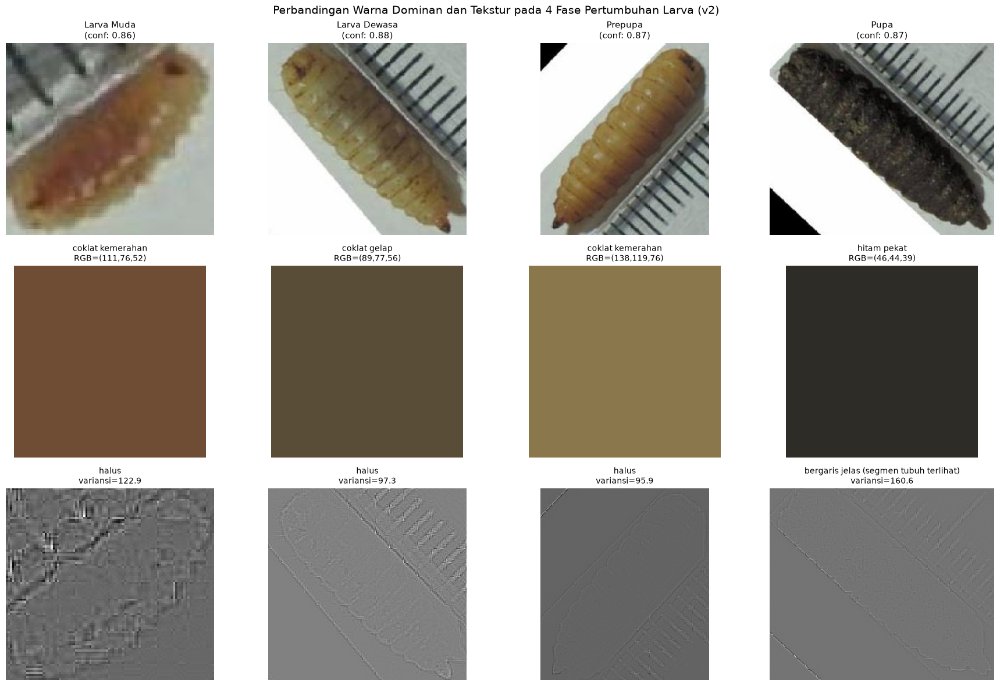

In [25]:
import matplotlib.pyplot as plt
import cv2

sampel_jernih = {
    "Larva Muda":   {"file": "rotate-output213_png.rf.6b4f55c01fea98c6bd3cf845c36141ff.jpg"},
    "Larva Dewasa": {"file": "rotate-output130_png.rf.77588a78b5a1d6acbb9e49774a519883.jpg"},
    "Prepupa":      {"file": "rotate-output46_png.rf.02eef111c665df94708e6e87c12d9d76.jpg"},
    "Pupa":         {"file": "rotate-output137_png.rf.0fb300ed83ff3e483f02be511612af1b.jpg"},
}

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for i, (fase, info) in enumerate(sampel_jernih.items()):
    img_path = paths["test"]["images"] / info["file"]
    detections, orig_img = detect_larvae(img_path, conf_threshold=0.25)
    det = next((d for d in detections if d["class_name"] == fase), detections[0])
    x1, y1, x2, y2 = det["bbox"]
    crop_img = orig_img[y1:y2, x1:x2]

    # --- Panggil fungsi BARU (v2, sudah buang piksel hijau background) ---
    R, G, B, cluster_info = get_dominant_color_v2(crop_img, k=3)
    kategori = classify_color_name(R, G, B)

    texture_info = analyze_texture(crop_img)
    gray = cv2.cvtColor(crop_img, cv2.COLOR_BGR2GRAY)
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)

    swatch = np.full((100, 100, 3), (R, G, B), dtype=np.uint8)

    axes[0, i].imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
    axes[0, i].set_title(f"{fase}\n(conf: {det['confidence']:.2f})", fontsize=11)
    axes[0, i].axis("off")

    axes[1, i].imshow(swatch)
    axes[1, i].set_title(f"{kategori}\nRGB=({R},{G},{B})", fontsize=10)
    axes[1, i].axis("off")

    axes[2, i].imshow(laplacian, cmap="gray")
    axes[2, i].set_title(f"{texture_info['texture_label']}\nvariansi={texture_info['laplacian_var']:.1f}", fontsize=10)
    axes[2, i].axis("off")

    print(f"{fase:15s} | RGB=({R},{G},{B}) | kategori={kategori}")

plt.suptitle("Perbandingan Warna Dominan dan Tekstur pada 4 Fase Pertumbuhan Larva (v2)", fontsize=14)
plt.tight_layout()
plt.savefig("outputs/gambar_perbandingan_v2.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

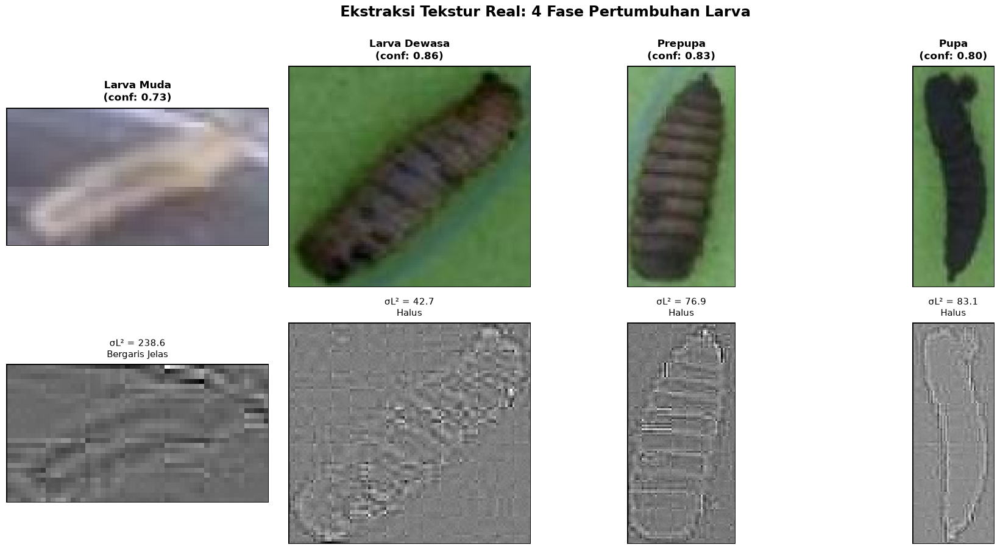


=== Ringkasan Hasil ===
Larva Muda      | σL² = 238.60 | Bergaris Jelas
Larva Dewasa    | σL² =  42.72 | Halus
Prepupa         | σL² =  76.91 | Halus
Pupa            | σL² =  83.13 | Halus


In [26]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

urutan_fase = ["Larva Muda", "Larva Dewasa", "Prepupa", "Pupa"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

hasil_ringkas = []

for i, fase in enumerate(urutan_fase):
    img_path = file_per_fase[fase]
    detections, orig_img = detect_larvae(img_path, conf_threshold=0.25)
    det = detections[0]
    x1, y1, x2, y2 = det["bbox"]
    crop_img = orig_img[y1:y2, x1:x2]

    gray = cv2.cvtColor(crop_img, cv2.COLOR_BGR2GRAY)
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    variansi = laplacian.var()
    kategori = klasifikasi_tekstur_lama(variansi)
    hasil_ringkas.append((fase, variansi, kategori))

    # Panel atas: crop larva
    ax_atas = axes[0, i]
    ax_atas.imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
    ax_atas.set_title(f"{fase}\n(conf: {det['confidence']:.2f})", fontsize=12, fontweight="bold", pad=8)
    ax_atas.axis("off")
    ax_atas.add_patch(patches.Rectangle((0,0), 1, 1, transform=ax_atas.transAxes,
                                          linewidth=2, edgecolor="black", facecolor="none"))

    # Panel bawah: peta Laplacian
    ax_bawah = axes[1, i]
    ax_bawah.imshow(laplacian, cmap="gray")
    ax_bawah.set_title(f"σL² = {variansi:.1f}\n{kategori}", fontsize=11, pad=8)
    ax_bawah.axis("off")
    ax_bawah.add_patch(patches.Rectangle((0,0), 1, 1, transform=ax_bawah.transAxes,
                                           linewidth=2, edgecolor="black", facecolor="none"))

plt.suptitle("Ekstraksi Tekstur Real: 4 Fase Pertumbuhan Larva", fontsize=17, fontweight="bold", y=1.0)
plt.tight_layout()
plt.savefig("outputs/ekstraksi_tekstur_4fase_border_final.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("\n=== Ringkasan Hasil ===")
for fase, var, kat in hasil_ringkas:
    print(f"{fase:15s} | σL² = {var:6.2f} | {kat}")

---
## 5. Pelatihan Model (Training YOLOv11s)

Training dijalankan menggunakan API `model.train()` dari Ultralytics, yang secara internal menjalankan seluruh proses: pemuatan data, augmentasi on-the-fly, forward pass melalui arsitektur (Backbone -> Neck -> Head), perhitungan loss, backpropagation, dan optimasi bobot menggunakan optimizer AdamW.

**Konfigurasi yang dipakai:**
- Model dasar: `yolo11s.pt` (pretrained di dataset COCO, di-*fine-tune* ke dataset larva)
- Epoch: 120 (dengan *early stopping*, `patience=30`)
- Ukuran citra: 640x640 (via letterbox preprocessing)
- Batch size: 16
- Optimizer: AdamW (dipilih otomatis oleh Ultralytics, `optimizer='auto'`)

**Catatan:** sel training di bawah diberi flag `RUN_TRAINING = False` secara default agar tidak menjalankan ulang training berjam-jam apabila model sudah tersedia. Ubah menjadi `True` hanya jika ingin melatih ulang dari awal.

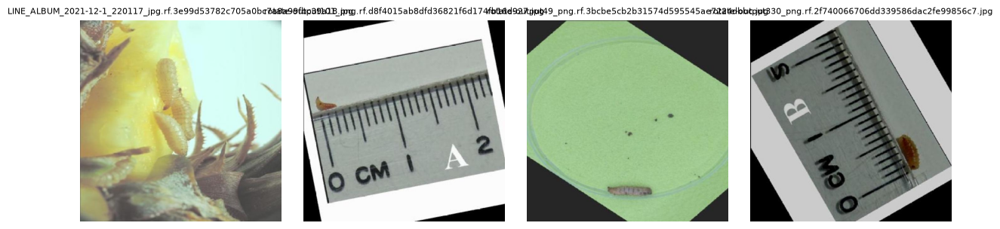

In [27]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

train_path = r"data/raw/train/images"  # Ganti dengan path folder gambar training Anda

images = [f for f in os.listdir(train_path)
          if f.endswith((".jpg", ".jpeg", ".png"))]

sample = random.sample(images, 4)

plt.figure(figsize=(12,3))

for i,img in enumerate(sample):
    plt.subplot(1,4,i+1)
    image = Image.open(os.path.join(train_path,img))
    plt.imshow(image)
    plt.title(img, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.savefig("sample_train.png", dpi=300)
plt.show()

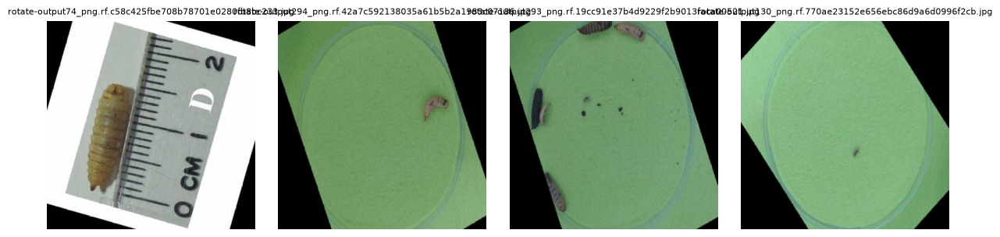

In [28]:
valid_path = r"data/raw/valid/images"

images = [f for f in os.listdir(valid_path)
          if f.endswith((".jpg",".png",".jpeg"))]

sample = random.sample(images,4)

plt.figure(figsize=(12,3))

for i,img in enumerate(sample):
    plt.subplot(1,4,i+1)
    image = Image.open(os.path.join(valid_path,img))
    plt.imshow(image)
    plt.title(img, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.savefig("sample_validation.png", dpi=300)
plt.show()

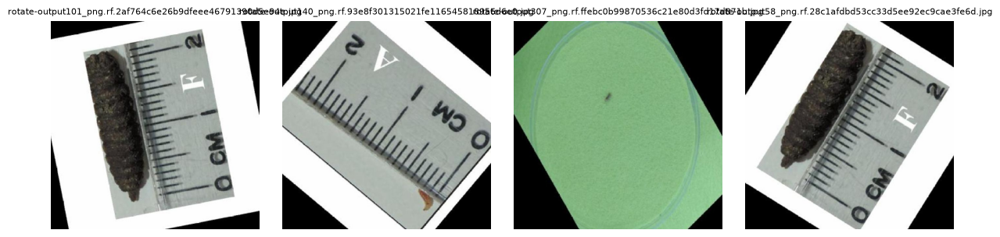

In [29]:
test_path = r"data/raw/test/images"

images = [f for f in os.listdir(test_path)
          if f.endswith((".jpg",".png",".jpeg"))]

sample = random.sample(images,4)

plt.figure(figsize=(12,3))

for i,img in enumerate(sample):
    plt.subplot(1,4,i+1)
    image = Image.open(os.path.join(test_path,img))
    plt.imshow(image)
    plt.title(img, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.savefig("sample_test.png", dpi=300)
plt.show()

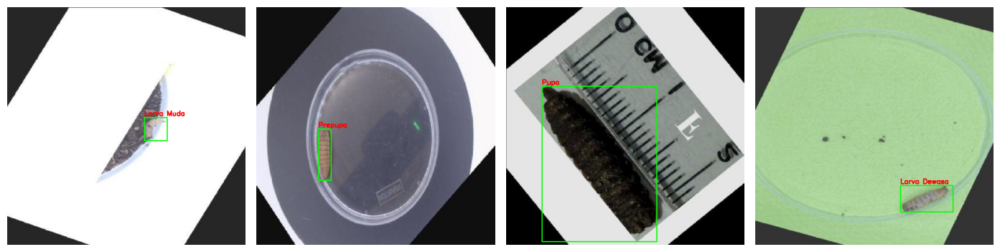

In [30]:
import os
import random
import cv2
import matplotlib.pyplot as plt

image_dir = r"data/raw/train/images"
label_dir = r"data/raw/train/labels"

classes = [
    "Larva Muda",
    "Larva Dewasa",
    "Prepupa",
    "Pupa"
]

files = random.sample(os.listdir(image_dir),4)

plt.figure(figsize=(14,4))

for i,file in enumerate(files):

    img = cv2.imread(os.path.join(image_dir,file))
    img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

    h,w,_ = img.shape

    label = file.replace(".jpg",".txt")

    with open(os.path.join(label_dir,label),"r") as f:

        for line in f:

            c,x,y,bw,bh = map(float,line.split())

            x1 = int((x-bw/2)*w)
            y1 = int((y-bh/2)*h)
            x2 = int((x+bw/2)*w)
            y2 = int((y+bh/2)*h)

            cv2.rectangle(img,(x1,y1),(x2,y2),(0,255,0),2)

            cv2.putText(
                img,
                classes[int(c)],
                (x1,y1-5),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255,0,0),
                2
            )

    plt.subplot(1,4,i+1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.savefig("sample_train_bbox.png",dpi=300)
plt.show()

In [31]:
RUN_TRAINING = False

if RUN_TRAINING:
    model = YOLO("yolo11s.pt")
    results = model.train(
        data=str(PROJECT_ROOT / "data.yaml"),
        epochs=120,
        imgsz=640,
        batch=16,
        patience=30,
        project="runs",
        name="yolov11s_bsf_larva",
        device=0 if torch.cuda.is_available() else "cpu",
        workers=4,
        optimizer="auto",
        seed=42,
        plots=True,
        save=True,
        save_period=10,
        amp=True,
        cache=False,
        **AUGMENTATION_CONFIG,
    )
else:
    print("RUN_TRAINING=False, melewati training. Gunakan model best.pt yang sudah ada.")


RUN_TRAINING=False, melewati training. Gunakan model best.pt yang sudah ada.


In [32]:
# Pecah jumlah parameter per bagian arsitektur: Backbone (0-10), Neck (11-22), Head (23)
backbone_params = 0
neck_params = 0
head_params = 0

for i, layer in enumerate(model.model.model):
    n_params = sum(p.numel() for p in layer.parameters())
    if i <= 10:
        backbone_params += n_params
    elif i <= 22:
        neck_params += n_params
    else:
        head_params += n_params

total_params = backbone_params + neck_params + head_params

print(f"{'Bagian':<12}{'Jumlah Parameter':>20}{'Persentase':>15}")
print("-" * 47)
print(f"{'Backbone':<12}{backbone_params:>20,}{backbone_params/total_params*100:>14.2f}%")
print(f"{'Neck':<12}{neck_params:>20,}{neck_params/total_params*100:>14.2f}%")
print(f"{'Head':<12}{head_params:>20,}{head_params/total_params*100:>14.2f}%")
print("-" * 47)
print(f"{'Total':<12}{total_params:>20,}{100.00:>14.2f}%")

Bagian          Jumlah Parameter     Persentase
-----------------------------------------------
Backbone               5,433,616         57.72%
Neck                   3,162,208         33.59%
Head                     818,524          8.69%
-----------------------------------------------
Total                  9,414,348        100.00%


In [33]:
TRAINED_RUN_DIR = PROJECT_ROOT / "runs" / "detect" / "runs" / "yolov11s_bsf_larva-7"
BEST_MODEL_SRC = TRAINED_RUN_DIR / "weights" / "best.pt"
BEST_MODEL_DST = PROJECT_ROOT / "models" / "yolov11_bsf" / "best.pt"

if BEST_MODEL_SRC.exists() and not BEST_MODEL_DST.exists():
    BEST_MODEL_DST.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(str(BEST_MODEL_SRC), str(BEST_MODEL_DST))
    print(f"Model disalin ke: {BEST_MODEL_DST}")

model = YOLO(str(BEST_MODEL_DST)) if BEST_MODEL_DST.exists() else YOLO(str(BEST_MODEL_SRC))

In [34]:
import pandas as pd

results_csv = TRAINED_RUN_DIR / "results.csv"
df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()

row = df.iloc[-1]  # epoch terakhir
print("Epoch:", int(row['epoch']))
print("train/box_loss:", row['train/box_loss'])
print("train/cls_loss:", row['train/cls_loss'])
print("train/dfl_loss:", row['train/dfl_loss'])

Epoch: 120
train/box_loss: 0.84064
train/cls_loss: 0.29237
train/dfl_loss: 0.97768


---
## 6. Pengujian (Evaluasi Model)

Model dievaluasi menggunakan **test set** (data yang sepenuhnya terpisah dari training/validasi) dengan empat metrik utama:

- **Precision** = TP / (TP + FP) — dari seluruh prediksi positif, berapa persen yang benar
- **Recall** = TP / (TP + FN) — dari seluruh objek aktual, berapa persen berhasil terdeteksi
- **mAP50** — rata-rata Average Precision pada ambang IoU 0.5
- **mAP50-95** — rata-rata Average Precision pada rentang ambang IoU 0.5 hingga 0.95 (lebih ketat)

In [35]:
TRAINED_RUN_DIR = PROJECT_ROOT / "runs" / "detect" / "runs" / "yolov11s_bsf_larva-7"
BEST_MODEL_SRC = TRAINED_RUN_DIR / "weights" / "best.pt"
BEST_MODEL_DST = PROJECT_ROOT / "models" / "yolov11_bsf" / "best.pt"

if BEST_MODEL_SRC.exists() and not BEST_MODEL_DST.exists():
    BEST_MODEL_DST.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(str(BEST_MODEL_SRC), str(BEST_MODEL_DST))
    print(f"Model disalin ke: {BEST_MODEL_DST}")

model = YOLO(str(BEST_MODEL_DST)) if BEST_MODEL_DST.exists() else YOLO(str(BEST_MODEL_SRC))

metrics = model.val(
    data=str(PROJECT_ROOT / "data.yaml"),
    split="test",
    imgsz=640,
    batch=16,
    device=0 if torch.cuda.is_available() else "cpu",
    plots=True,
    workers=0,
)

print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"Precision (mean): {metrics.box.mp:.4f}")
print(f"Recall (mean): {metrics.box.mr:.4f}")

print(f"\n{'Kelas':<15}{'Precision':<12}{'Recall':<12}{'mAP50':<10}{'mAP50-95'}")
print("-" * 65)
for i, name in enumerate(CLASS_NAMES):
    print(f"{name:<15}{metrics.box.p[i]:<12.4f}{metrics.box.r[i]:<12.4f}"
          f"{metrics.box.ap50[i]:<10.4f}{metrics.box.ap[i]:.4f}")


Ultralytics 8.4.89  Python-3.12.8 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
YOLO11s summary (fused): 101 layers, 9,414,348 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access  (ping: 0.10.1 ms, read: 231.090.9 MB/s, size: 27.9 KB)
val: Scanning C:\bsf_larva\data\raw\test\labels.cache... 578 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 578/578  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 3.2it/s 11.4s0.3s
                   all        578        962      0.972      0.832      0.872      0.676
            Larva Muda        257        380      0.957      0.687       0.72       0.49
          Larva Dewasa        212        358      0.943      0.698      0.808      0.611
               Prepupa        109        109      0.989          1      0.995      0.816
                  Pupa        115        115          1      0.941      0.965      0.787
Speed: 0.6ms preprocess,

### 6.1 Confusion Matrix

**Confusion matrix** menunjukkan sebaran prediksi model terhadap label sebenarnya (ground truth) untuk tiap kelas, dalam bentuk matriks. Baris merepresentasikan kelas prediksi model, kolom merepresentasikan kelas sebenarnya (atau sebaliknya, tergantung konvensi Ultralytics). Nilai pada diagonal menunjukkan jumlah prediksi **benar** untuk tiap kelas, sedangkan nilai di luar diagonal menunjukkan **kesalahan klasifikasi** — larva dari kelas tertentu yang salah diprediksi sebagai kelas lain.

Ultralytics otomatis membuat confusion matrix (versi jumlah mentah dan versi ternormalisasi per baris) setiap kali `model.val(plots=True)` dijalankan, disimpan di folder hasil validasi. Confusion matrix ini sangat berguna untuk mengidentifikasi **kelas mana yang paling sering tertukar** — pada proyek ini, dugaan awal adalah Larva Muda dan Larva Dewasa paling sering tertukar karena kemiripan visual yang tinggi di antara keduanya, dibanding dengan Prepupa dan Pupa yang punya ciri visual sangat khas.

Folder hasil validasi terbaru: runs\detect\val-31


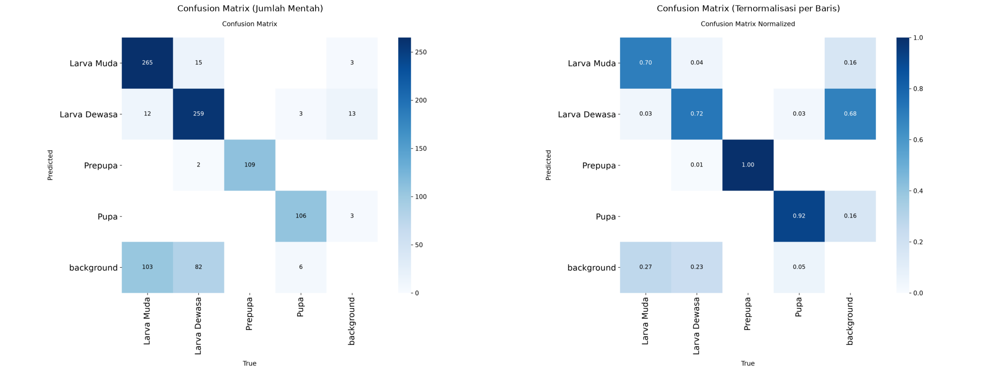

In [36]:
import matplotlib.image as mpimg

# Ultralytics menyimpan confusion matrix di folder hasil model.val() terakhir,
# biasanya di runs/detect/val (atau val2, val3, dst jika dijalankan berulang kali)
val_dirs = sorted(Path("runs/detect").glob("val*"), key=lambda p: p.stat().st_mtime, reverse=True)
latest_val_dir = val_dirs[0] if val_dirs else None

if latest_val_dir:
    print("Folder hasil validasi terbaru:", latest_val_dir)

    cm_raw = latest_val_dir / "confusion_matrix.png"
    cm_norm = latest_val_dir / "confusion_matrix_normalized.png"

    fig, axes = plt.subplots(1, 2, figsize=(20, 9))
    if cm_raw.exists():
        axes[0].imshow(mpimg.imread(str(cm_raw)))
        axes[0].set_title("Confusion Matrix (Jumlah Mentah)")
    else:
        axes[0].text(0.5, 0.5, "File tidak ditemukan", ha="center")
    axes[0].axis("off")

    if cm_norm.exists():
        axes[1].imshow(mpimg.imread(str(cm_norm)))
        axes[1].set_title("Confusion Matrix (Ternormalisasi per Baris)")
    else:
        axes[1].text(0.5, 0.5, "File tidak ditemukan", ha="center")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Belum ada hasil model.val() tersimpan. Jalankan ulang sel evaluasi (Bagian 7) terlebih dahulu.")


                              Aktual: Larva Muda  Aktual: Larva Dewasa  \
Prediksi: Larva Muda                         264                    15   
Prediksi: Larva Dewasa                         6                   248   
Prediksi: Prepupa                              0                     0   
Prediksi: Pupa                                 0                     0   
Prediksi: (tidak terdeteksi)                 110                    95   

                              Aktual: Prepupa  Aktual: Pupa  \
Prediksi: Larva Muda                        0             0   
Prediksi: Larva Dewasa                      0             0   
Prediksi: Prepupa                         109             0   
Prediksi: Pupa                              0           107   
Prediksi: (tidak terdeteksi)                0             8   

                              Aktual: (tidak terdeteksi)  
Prediksi: Larva Muda                                   5  
Prediksi: Larva Dewasa                                10  

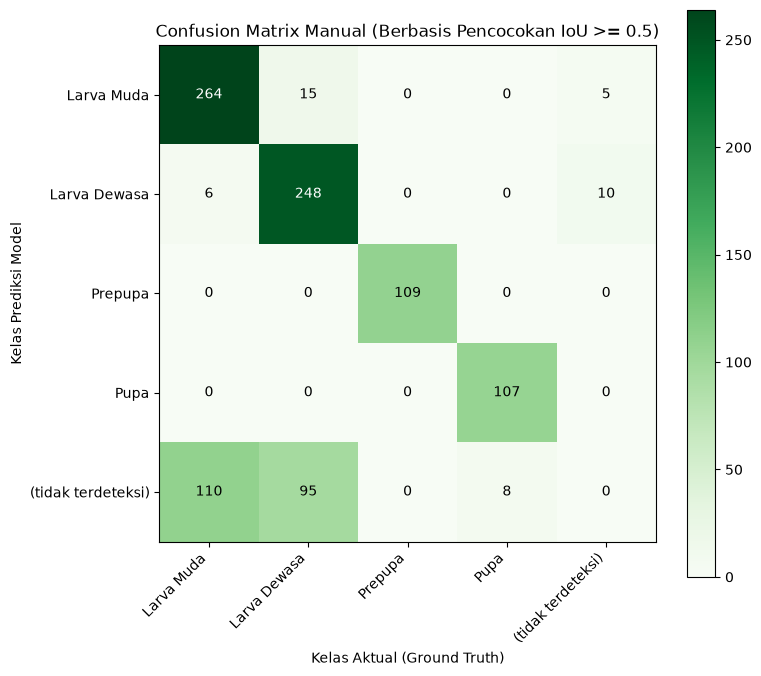

In [37]:
# Alternatif: menghitung confusion matrix secara manual dari hasil prediksi pada test set,
# berguna jika ingin analisis lebih lanjut (misal export ke CSV) di luar plot bawaan Ultralytics.
from collections import defaultdict

def compute_confusion_matrix(model, images_folder, labels_folder, class_names, conf_threshold=0.25, iou_threshold=0.5):
    """
    Menghitung confusion matrix sederhana berbasis pencocokan IoU terbaik
    antara prediksi dan ground truth pada setiap gambar.
    """
    n = len(class_names)
    matrix = np.zeros((n + 1, n + 1), dtype=int)  # +1 untuk kelas 'background'/tidak terdeteksi

    def iou(box1, box2):
        x1 = max(box1[0], box2[0]); y1 = max(box1[1], box2[1])
        x2 = min(box1[2], box2[2]); y2 = min(box1[3], box2[3])
        inter = max(0, x2 - x1) * max(0, y2 - y1)
        area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
        area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])
        union = area1 + area2 - inter
        return inter / union if union > 0 else 0

    image_files = list(Path(images_folder).glob("*.*"))
    for img_path in image_files:
        label_path = Path(labels_folder) / f"{img_path.stem}.txt"
        if not label_path.exists():
            continue
        img = cv2.imread(str(img_path))
        h, w = img.shape[:2]

        gt_boxes = []
        for row in read_yolo_label(label_path):
            cls_id = int(row[0])
            xc, yc, bw, bh = map(float, row[1:5])
            x1, y1 = (xc - bw/2) * w, (yc - bh/2) * h
            x2, y2 = (xc + bw/2) * w, (yc + bh/2) * h
            gt_boxes.append({"cls": cls_id, "box": [x1, y1, x2, y2], "matched": False})

        results = model.predict(source=str(img_path), conf=conf_threshold, verbose=False)
        pred_boxes = []
        for box in results[0].boxes:
            pred_boxes.append({"cls": int(box.cls[0]), "box": box.xyxy[0].tolist()})

        for pred in pred_boxes:
            best_iou, best_gt = 0, None
            for gt in gt_boxes:
                if gt["matched"]:
                    continue
                val = iou(pred["box"], gt["box"])
                if val > best_iou:
                    best_iou, best_gt = val, gt
            if best_iou >= iou_threshold and best_gt is not None:
                matrix[pred["cls"], best_gt["cls"]] += 1
                best_gt["matched"] = True
            else:
                matrix[pred["cls"], n] += 1  # prediksi tanpa pasangan ground truth (false positive)

        for gt in gt_boxes:
            if not gt["matched"]:
                matrix[n, gt["cls"]] += 1  # ground truth tidak terdeteksi (false negative)

    return matrix

# Jalankan pada test set (bisa memakan waktu beberapa menit tergantung jumlah gambar)
cm_manual = compute_confusion_matrix(model, paths["test"]["images"], paths["test"]["labels"], CLASS_NAMES)

labels_with_bg = CLASS_NAMES + ["(tidak terdeteksi)"]
df_cm = pd.DataFrame(cm_manual, index=[f"Prediksi: {c}" for c in labels_with_bg],
                      columns=[f"Aktual: {c}" for c in labels_with_bg])
print(df_cm)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm_manual, cmap="Greens")
ax.set_xticks(range(len(labels_with_bg))); ax.set_xticklabels(labels_with_bg, rotation=45, ha="right")
ax.set_yticks(range(len(labels_with_bg))); ax.set_yticklabels(labels_with_bg)
ax.set_xlabel("Kelas Aktual (Ground Truth)"); ax.set_ylabel("Kelas Prediksi Model")
ax.set_title("Confusion Matrix Manual (Berbasis Pencocokan IoU >= 0.5)")
for i in range(cm_manual.shape[0]):
    for j in range(cm_manual.shape[1]):
        ax.text(j, i, cm_manual[i, j], ha="center", va="center",
                 color="white" if cm_manual[i, j] > cm_manual.max()/2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()


In [38]:
import torch

# Ambil satu citra sampel dari data latih
sample_img_path = list(paths["train"]["images"].glob("*.*"))[0]
img = cv2.imread(str(sample_img_path))

# dan tangkap 4 nilai return-nya
img_letterbox, scale, pad_x, pad_y = letterbox_preprocess(img, target_size=640)

tensor_input = torch.from_numpy(img_letterbox).permute(2, 0, 1).unsqueeze(0).float() / 255.0

# PERBAIKAN TAMBAHAN: pindahkan tensor ke device yang sama dengan model (GPU/CPU)
device = next(model.model.parameters()).device
tensor_input = tensor_input.to(device)
print(f"Model berada di device: {device}")

print(f"Citra sampel: {sample_img_path.name}")
print(f"Ukuran tensor input: {tuple(tensor_input.shape)}  (Batch, Channel, Height, Width)\n")

x = tensor_input
outputs_per_layer = {}

with torch.no_grad():
    for i, layer in enumerate(model.model.model):
        if layer.f == -1:
            inp = x
        elif isinstance(layer.f, list):
            inp = [x if j == -1 else outputs_per_layer[j] for j in layer.f]
        else:
            inp = outputs_per_layer[layer.f]

        x = layer(inp)
        outputs_per_layer[i] = x

        if isinstance(x, torch.Tensor):
            shape = tuple(x.shape)
            print(f"Layer {i:2d}  {layer.__class__.__name__:10s}  "
                  f"output shape = {shape}  "
                  f"(Channel={shape[1]}, H={shape[2]}, W={shape[3]})")

        if i == 10:
            break

Model berada di device: cuda:0
Citra sampel: -_jpg.rf.400e05222c259011470d1261082c2db1.jpg
Ukuran tensor input: (1, 3, 640, 640)  (Batch, Channel, Height, Width)

Layer  0  Conv        output shape = (1, 32, 320, 320)  (Channel=32, H=320, W=320)
Layer  1  Conv        output shape = (1, 64, 160, 160)  (Channel=64, H=160, W=160)
Layer  2  C3k2        output shape = (1, 128, 160, 160)  (Channel=128, H=160, W=160)
Layer  3  Conv        output shape = (1, 128, 80, 80)  (Channel=128, H=80, W=80)
Layer  4  C3k2        output shape = (1, 256, 80, 80)  (Channel=256, H=80, W=80)
Layer  5  Conv        output shape = (1, 256, 40, 40)  (Channel=256, H=40, W=40)
Layer  6  C3k2        output shape = (1, 256, 40, 40)  (Channel=256, H=40, W=40)
Layer  7  Conv        output shape = (1, 512, 20, 20)  (Channel=512, H=20, W=20)
Layer  8  C3k2        output shape = (1, 512, 20, 20)  (Channel=512, H=20, W=20)
Layer  9  SPPF        output shape = (1, 512, 20, 20)  (Channel=512, H=20, W=20)
Layer 10  C2PSA    

In [39]:
# Cek apakah fungsi-fungsi penting sudah ter-load
for nama_fungsi in ["detect_larvae", "get_dominant_color", "classify_color_name", "analyze_texture", "model", "paths"]:
    status = "✓ SUDAH ADA" if nama_fungsi in dir() else "✗ BELUM ADA"
    print(f"{nama_fungsi:25s} {status}")

detect_larvae             ✓ SUDAH ADA
get_dominant_color        ✓ SUDAH ADA
classify_color_name       ✓ SUDAH ADA
analyze_texture           ✓ SUDAH ADA
model                     ✓ SUDAH ADA
paths                     ✓ SUDAH ADA


---
## 7. Klasifikasi

### 7.1 Modul Rekomendasi Waktu Panen (Rule-Based)

Rekomendasi panen dihasilkan melalui pendekatan **rule-based** (berbasis aturan), bukan model prediktif tambahan. Logikanya mempertimbangkan **proporsi fase dominan** dari seluruh larva yang terdeteksi pada satu citra, didasarkan pada prinsip bahwa fase Prepupa adalah waktu panen optimal secara nutrisi dan ekonomi (sebelum larva bermetamorfosis menjadi Pupa yang nilainya menurun).

In [40]:
def count_larvae_per_phase(detections):
    phase_counts = Counter(det["class_name"] for det in detections)
    result = {name: phase_counts.get(name, 0) for name in CLASS_NAMES}
    result["Total"] = sum(result.values())
    return result


def generate_harvest_recommendation(phase_counts):
    total = phase_counts.get("Total", sum(phase_counts.get(name, 0) for name in CLASS_NAMES))
    if total == 0:
        return {"status": "Tidak Ada Data", "rekomendasi": "Tidak ada larva terdeteksi pada gambar.", "urgensi": "none"}

    pct = {name: phase_counts.get(name, 0) / total * 100 for name in CLASS_NAMES}
    dominant_phase = max(pct, key=pct.get)
    dominant_pct = pct[dominant_phase]

    if dominant_phase == "Larva Muda" and dominant_pct > 40:
        return {"status": "Belum Waktunya Panen",
                "rekomendasi": f"Mayoritas larva masih dalam fase Larva Muda ({dominant_pct:.1f}%). Disarankan menunggu 7-10 hari lagi.",
                "urgensi": "low", "estimasi_hari": "7-10 hari"}
    elif dominant_phase == "Larva Dewasa" and dominant_pct > 35:
        return {"status": "Mendekati Waktu Panen",
                "rekomendasi": f"Mayoritas larva dalam fase Larva Dewasa ({dominant_pct:.1f}%). Pantau tiap 2-3 hari.",
                "urgensi": "medium", "estimasi_hari": "3-5 hari"}
    elif dominant_phase == "Prepupa" and dominant_pct > 25:
        return {"status": "WAKTU PANEN OPTIMAL",
                "rekomendasi": f"Larva didominasi fase Prepupa ({dominant_pct:.1f}%). Disarankan panen SEGERA.",
                "urgensi": "high", "estimasi_hari": "1-2 hari"}
    elif dominant_phase == "Pupa" and dominant_pct > 20:
        return {"status": "Waktu Panen Terlewat",
                "rekomendasi": f"Sebagian larva sudah menjadi Pupa ({dominant_pct:.1f}%). Segera panen sisa Prepupa.",
                "urgensi": "critical", "estimasi_hari": "Segera"}
    else:
        return {"status": "Kondisi Campuran",
                "rekomendasi": f"Populasi tersebar merata (dominan: {dominant_phase} {dominant_pct:.1f}%). Monitor berkala.",
                "urgensi": "medium", "estimasi_hari": "Monitor 3-5 hari"}


### 7.2 Pipeline Analisis Terintegrasi (Deteksi + Klasifikasi Fase + Rekomendasi)

Fungsi berikut menggabungkan seluruh tahap: deteksi YOLOv11 -> ekstraksi ciri visual (K-Means + Laplacian) per larva -> penghitungan jumlah per fase -> rekomendasi panen, menjadi satu pipeline yang menghasilkan output terstruktur (siap dikonversi ke JSON).

### 7.3 Visualisasi Hasil Deteksi dengan Bounding Box pada Data Uji

Sel berikut menampilkan beberapa contoh hasil deteksi model pada citra dari **test set**, lengkap dengan bounding box, label kelas, dan confidence score — berguna sebagai lampiran visual keberhasilan (dan potensi kesalahan) deteksi model pada Bab IV. Sel ini hanya memanggil ulang `detect_larvae` (fungsi yang sama dari Bagian 10, tidak diubah).

In [41]:
def detect_larvae(image_path, conf_threshold=0.25):
    with torch.no_grad():
        results = model.predict(source=str(image_path), conf=conf_threshold, verbose=False)
    result = results[0]
    detections = []
    for box in result.boxes:
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        detections.append({
            "class_id": cls_id,
            "class_name": CLASS_NAMES[cls_id],
            "confidence": conf,
            "bbox": (int(x1), int(y1), int(x2), int(y2)),
        })
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return detections, result.orig_img


def full_analysis_pipeline(image_path, conf_threshold=0.25):
    detections, orig_img = detect_larvae(image_path, conf_threshold)
    larvae_details = []
    for det in detections:
        x1, y1, x2, y2 = det["bbox"]
        crop = orig_img[max(y1,0):y2, max(x1,0):x2]
        traits = {}
        if crop.size > 0:
            r, g, b = get_dominant_color(crop)
            traits = {"color_name": classify_color_name(r, g, b),
                      "texture_label": analyze_texture(crop)["texture_label"]}
        larvae_details.append({"class_name": det["class_name"], "confidence": round(det["confidence"], 4),
                               "bbox": det["bbox"], **traits})
    phase_counts = count_larvae_per_phase(detections)
    recommendation = generate_harvest_recommendation(phase_counts)
    return {"total_larvae_detected": phase_counts["Total"],
            "phase_counts": {name: phase_counts[name] for name in CLASS_NAMES},
            "larvae_details": larvae_details,
            "harvest_recommendation": recommendation}


# Test pipeline lengkap
sample_test_img = random.choice(list(paths["test"]["images"].glob("*.*")))
result_json = full_analysis_pipeline(sample_test_img)
print(json.dumps(result_json, indent=2, ensure_ascii=False))


{
  "total_larvae_detected": 1,
  "phase_counts": {
    "Larva Muda": 1,
    "Larva Dewasa": 0,
    "Prepupa": 0,
    "Pupa": 0
  },
  "larvae_details": [
    {
      "class_name": "Larva Muda",
      "confidence": 0.8224,
      "bbox": [
        472,
        54,
        527,
        139
      ],
      "color_name": "coklat gelap",
      "texture_label": "halus"
    }
  ],
  "harvest_recommendation": {
    "status": "Belum Waktunya Panen",
    "rekomendasi": "Mayoritas larva masih dalam fase Larva Muda (100.0%). Disarankan menunggu 7-10 hari lagi.",
    "urgensi": "low",
    "estimasi_hari": "7-10 hari"
  }
}


Folder hasil validasi terbaru: runs\detect\val-31


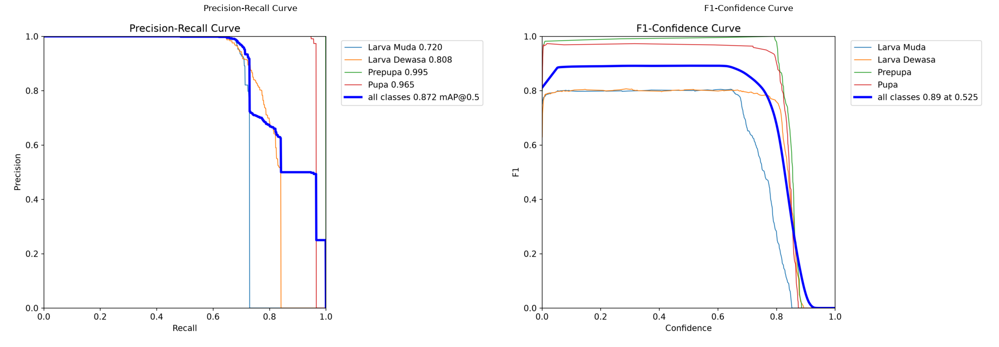

In [42]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from pathlib import Path

# Ultralytics menyimpan PR curve dan F1 curve di folder hasil model.val() terakhir,
# biasanya di runs/detect/val (atau val2, val3, dst jika dijalankan berulang kali)
val_dirs = sorted(Path("runs/detect").glob("val*"), key=lambda p: p.stat().st_mtime, reverse=True)
latest_val_dir = val_dirs[0] if val_dirs else None

if latest_val_dir:
    print("Folder hasil validasi terbaru:", latest_val_dir)

    pr_curve_path = latest_val_dir / "BoxPR_curve.png"
    f1_curve_path = latest_val_dir / "BoxF1_curve.png"

    fig, axes = plt.subplots(1, 2, figsize=(20, 9))

    # Panel kiri: PR Curve
    if pr_curve_path.exists():
        axes[0].imshow(mpimg.imread(str(pr_curve_path)))
        axes[0].set_title("Precision-Recall Curve")
    else:
        axes[0].text(0.5, 0.5, "File tidak ditemukan", ha="center")
    axes[0].axis("off")

    # Panel kanan: F1-Confidence Curve
    if f1_curve_path.exists():
        axes[1].imshow(mpimg.imread(str(f1_curve_path)))
        axes[1].set_title("F1-Confidence Curve")
    else:
        axes[1].text(0.5, 0.5, "File tidak ditemukan", ha="center")
    axes[1].axis("off")

    plt.tight_layout()
    plt.savefig("gambar_3_11_3_12_pr_f1_curve.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("Belum ada hasil model.val() tersimpan. Jalankan ulang sel evaluasi (Cell 34) terlebih dahulu.")

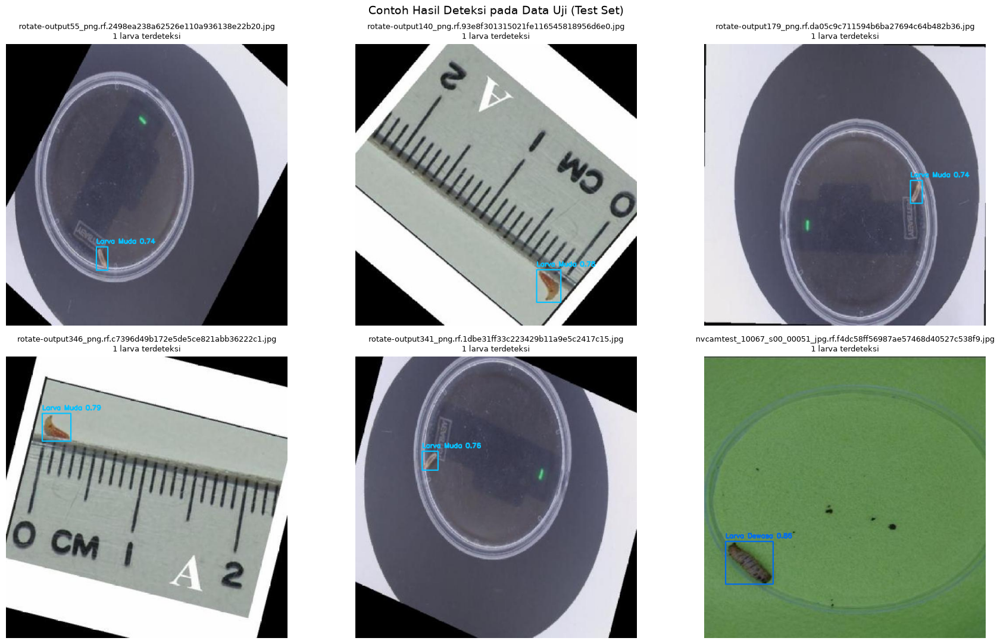

In [43]:
def visualize_detection_result(image_path, conf_threshold=0.25):
    detections, orig_img = detect_larvae(image_path, conf_threshold)
    img_display = orig_img.copy()
    phase_colors = {
        "Larva Muda": (255, 193, 7), "Larva Dewasa": (239, 108, 0),
        "Prepupa": (141, 110, 99), "Pupa": (66, 66, 66),
    }
    for det in detections:
        x1, y1, x2, y2 = det["bbox"]
        color = phase_colors.get(det["class_name"], (0, 255, 0))
        cv2.rectangle(img_display, (x1, y1), (x2, y2), color, 2)
        label = f"{det['class_name']} {det['confidence']:.2f}"
        cv2.putText(img_display, label, (x1, max(y1-8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    return cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB), len(detections)

sample_test_images = random.sample(list(paths["test"]["images"].glob("*.*")), min(6, len(list(paths["test"]["images"].glob("*.*")))))

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, img_path in zip(axes.flatten(), sample_test_images):
    img_rgb, n_det = visualize_detection_result(img_path)
    ax.imshow(img_rgb)
    ax.set_title(f"{img_path.name}\n{n_det} larva terdeteksi", fontsize=9)
    ax.axis("off")
plt.suptitle("Contoh Hasil Deteksi pada Data Uji (Test Set)", fontsize=14)
plt.tight_layout()
plt.savefig("outputs/contoh_hasil_deteksi.png", dpi=150, bbox_inches="tight")
plt.show()


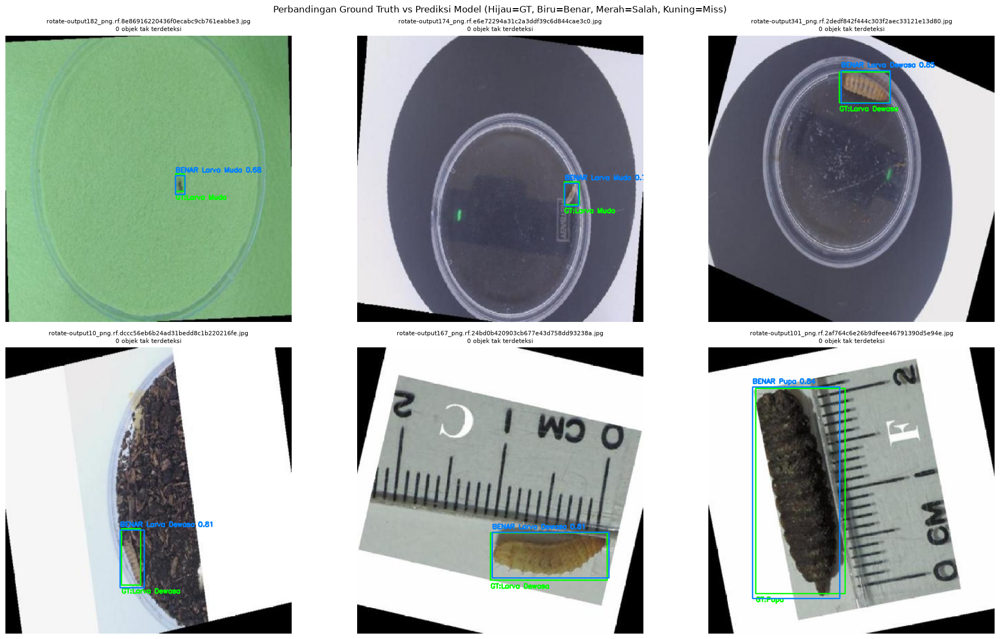

In [44]:
import cv2
import random
import matplotlib.pyplot as plt
from pathlib import Path

def read_yolo_label(label_path):
    with open(label_path, "r") as f:
        return [line.strip().split() for line in f.readlines() if line.strip()]

def yolo_to_xyxy(row, img_w, img_h):
    """Konversi label YOLO (class_id, xc, yc, w, h ternormalisasi) ke koordinat piksel x1,y1,x2,y2."""
    cls_id, xc, yc, bw, bh = int(row[0]), float(row[1]), float(row[2]), float(row[3]), float(row[4])
    x1 = int((xc - bw / 2) * img_w)
    y1 = int((yc - bh / 2) * img_h)
    x2 = int((xc + bw / 2) * img_w)
    y2 = int((yc + bh / 2) * img_h)
    return cls_id, (x1, y1, x2, y2)

def hitung_iou(box1, box2):
    x1 = max(box1[0], box2[0]); y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2]); y2 = min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0

def visualize_gt_vs_pred(image_path, label_path, conf_threshold=0.25, iou_threshold=0.5):
    """
    Menampilkan ground truth (hijau) dan prediksi model (biru/merah) dalam satu gambar.
    Kotak biru = prediksi benar (IoU>=0.5 & kelas cocok), kotak merah = prediksi salah.
    Kotak hijau putus-putus = ground truth yang tidak terdeteksi sama sekali (miss/FN).
    """
    with torch.no_grad():
        results = model.predict(source=str(image_path), conf=conf_threshold, verbose=False)
    result = results[0]
    img = result.orig_img.copy()
    h, w = img.shape[:2]

    # Ambil ground truth
    gt_rows = read_yolo_label(label_path)
    gt_boxes = [yolo_to_xyxy(r, w, h) for r in gt_rows]
    gt_matched = [False] * len(gt_boxes)

    # Gambar ground truth (hijau tipis dulu, nanti ditimpa jadi putus-putus jika miss)
    for cls_id, bbox in gt_boxes:
        x1, y1, x2, y2 = bbox
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, f"GT:{CLASS_NAMES[cls_id]}", (x1, min(y2+18, h-5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    # Cocokkan tiap prediksi dengan ground truth terbaik
    for box in result.boxes:
        cls_pred = int(box.cls[0])
        conf = float(box.conf[0])
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        pred_box = (x1, y1, x2, y2)

        iou_terbaik, idx_terbaik = 0, -1
        for j, (cls_gt, gt_box) in enumerate(gt_boxes):
            iou = hitung_iou(pred_box, gt_box)
            if iou > iou_terbaik:
                iou_terbaik, idx_terbaik = iou, j

        benar = (iou_terbaik >= iou_threshold and idx_terbaik != -1
                  and gt_boxes[idx_terbaik][0] == cls_pred)
        if benar:
            gt_matched[idx_terbaik] = True
            warna = (255, 128, 0)   # biru = prediksi benar
            label = f"BENAR {CLASS_NAMES[cls_pred]} {conf:.2f}"
        else:
            warna = (0, 0, 255)     # merah = prediksi salah
            label = f"SALAH {CLASS_NAMES[cls_pred]} {conf:.2f}"

        cv2.rectangle(img, (x1, y1), (x2, y2), warna, 2)
        cv2.putText(img, label, (x1, max(y1-8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, warna, 2)

    # Tandai ground truth yang tidak pernah terdeteksi (miss / False Negative)
    n_miss = 0
    for matched, (cls_id, bbox) in zip(gt_matched, gt_boxes):
        if not matched:
            x1, y1, x2, y2 = bbox
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 200, 255), 2)
            cv2.putText(img, "MISS (tak terdeteksi)", (x1, min(y2+36, h-5)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 200, 255), 2)
            n_miss += 1

    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB), n_miss


# Cari beberapa contoh citra test yang punya potensi kasus salah (miss/FP) untuk perbandingan
sample_test_images = random.sample(
    list(paths["test"]["images"].glob("*.*")),
    min(6, len(list(paths["test"]["images"].glob("*.*"))))
)

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, img_path in zip(axes.flatten(), sample_test_images):
    label_path = paths["test"]["labels"] / f"{img_path.stem}.txt"
    if not label_path.exists():
        ax.axis("off")
        continue
    img_rgb, n_miss = visualize_gt_vs_pred(img_path, label_path)
    ax.imshow(img_rgb)
    ax.set_title(f"{img_path.name}\n{n_miss} objek tak terdeteksi", fontsize=8)
    ax.axis("off")

plt.suptitle("Perbandingan Ground Truth vs Prediksi Model (Hijau=GT, Biru=Benar, Merah=Salah, Kuning=Miss)",
             fontsize=12)
plt.tight_layout()
plt.savefig("gambar_3_15_gt_vs_prediksi.png", dpi=200, bbox_inches="tight")
plt.show()

Ditemukan 6 citra dengan prediksi 100% benar


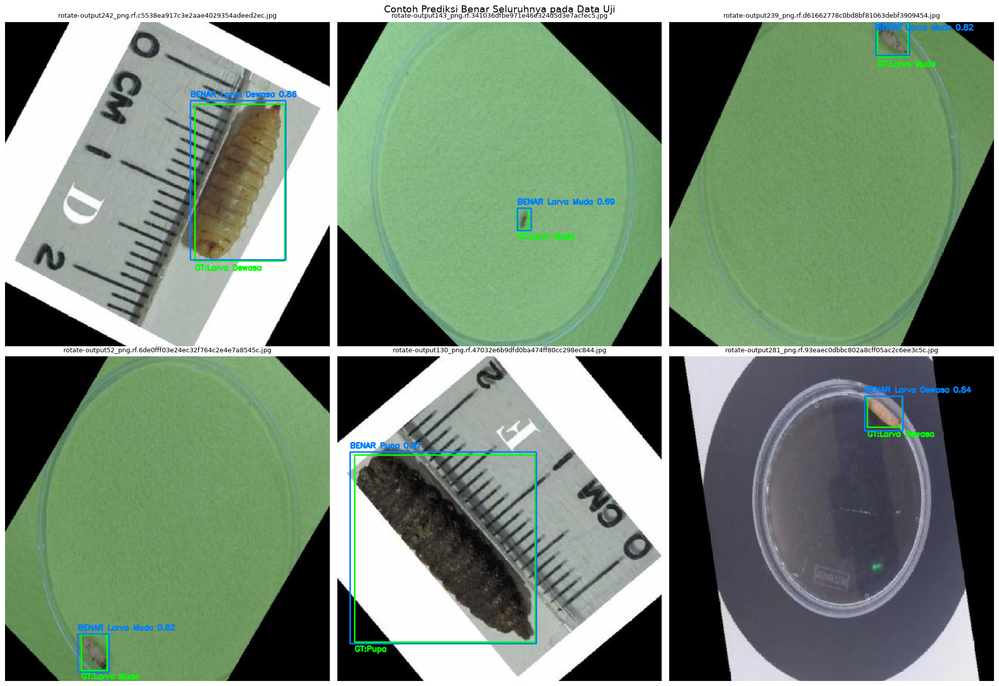

In [45]:
import random
import matplotlib.pyplot as plt

# --- Cari citra test yang SEMUA prediksinya benar (tidak ada SALAH maupun MISS) ---
kandidat_benar = []
semua_test_images = list(paths["test"]["images"].glob("*.*"))
random.shuffle(semua_test_images)

for img_path in semua_test_images:
    label_path = paths["test"]["labels"] / f"{img_path.stem}.txt"
    if not label_path.exists():
        continue

    with torch.no_grad():
        results = model.predict(source=str(img_path), conf=0.25, verbose=False)
    result = results[0]
    h, w = result.orig_img.shape[:2]

    gt_rows = read_yolo_label(label_path)
    gt_boxes = [yolo_to_xyxy(r, w, h) for r in gt_rows]

    # Lewati citra tanpa larva sama sekali (tidak informatif untuk contoh "benar")
    if len(gt_boxes) == 0:
        continue

    gt_matched = [False] * len(gt_boxes)
    semua_prediksi_benar = True

    for box in result.boxes:
        cls_pred = int(box.cls[0])
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        pred_box = (x1, y1, x2, y2)

        iou_terbaik, idx_terbaik = 0, -1
        for j, (cls_gt, gt_box) in enumerate(gt_boxes):
            iou = hitung_iou(pred_box, gt_box)
            if iou > iou_terbaik:
                iou_terbaik, idx_terbaik = iou, j

        benar = (iou_terbaik >= 0.5 and idx_terbaik != -1 and gt_boxes[idx_terbaik][0] == cls_pred)
        if benar:
            gt_matched[idx_terbaik] = True
        else:
            semua_prediksi_benar = False
            break

    ada_miss = any(not m for m in gt_matched)

    # Ambil hanya jika: semua prediksi benar, tidak ada objek yang terlewat (miss),
    # dan jumlah larva pada citra lebih dari 1 (lebih menarik daripada 1 larva saja)
    if semua_prediksi_benar and not ada_miss and len(gt_boxes) >= 1:
        kandidat_benar.append(img_path)

    if len(kandidat_benar) >= 6:
        break

print(f"Ditemukan {len(kandidat_benar)} citra dengan prediksi 100% benar")

# --- Tampilkan hasilnya ---
n = len(kandidat_benar)
cols = 3
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(20, 7 * rows))
axes = axes.flatten() if n > 1 else [axes]

for ax, img_path in zip(axes, kandidat_benar):
    label_path = paths["test"]["labels"] / f"{img_path.stem}.txt"
    img_rgb, n_miss = visualize_gt_vs_pred(img_path, label_path, conf_threshold=0.25)
    ax.imshow(img_rgb)
    ax.set_title(img_path.name, fontsize=9)
    ax.axis("off")

# Sembunyikan axes kosong jika jumlah kandidat kurang dari grid
for ax in axes[len(kandidat_benar):]:
    ax.axis("off")

plt.suptitle("Contoh Prediksi Benar Seluruhnya pada Data Uji", fontsize=14)
plt.tight_layout()
plt.savefig("gambar_3_15_contoh_benar.png", dpi=200, bbox_inches="tight")
plt.show()

=== rotate-output86_png.rf.b7d932c57efc0c6c1519a30f83c10922.jpg ===


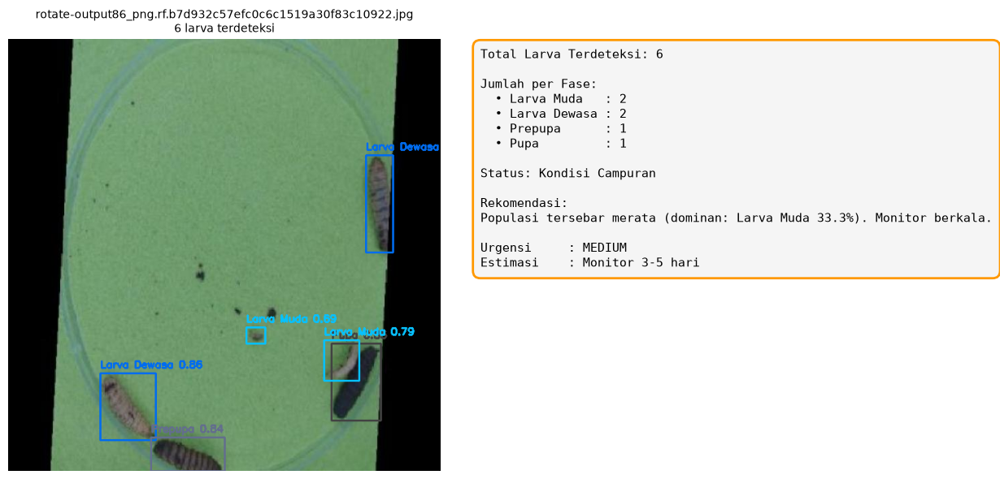

=== nvcamtest_8469_s00_00026_jpg.rf.5ca11bd52e6facd59f6c9ead3122d4f7.jpg ===


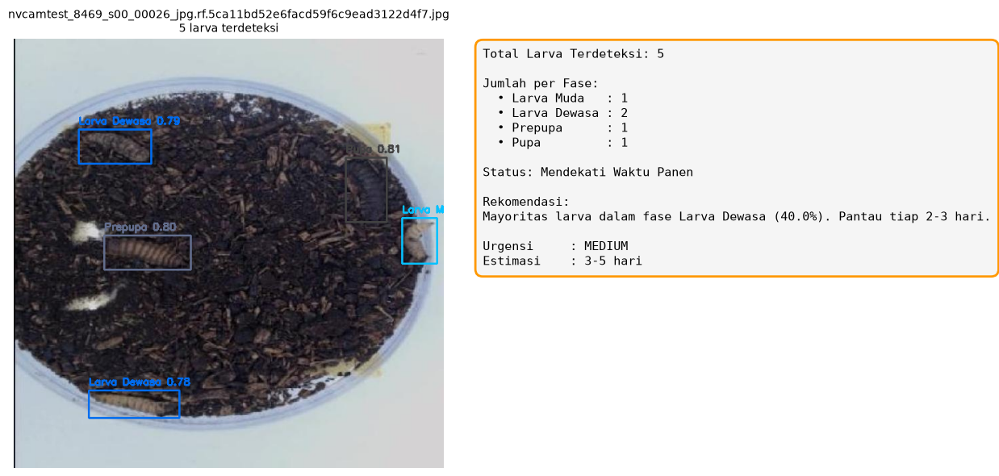

=== rotate-output134_png.rf.c36cf1d8c1c818c0f6d5648d88abcd9c.jpg ===


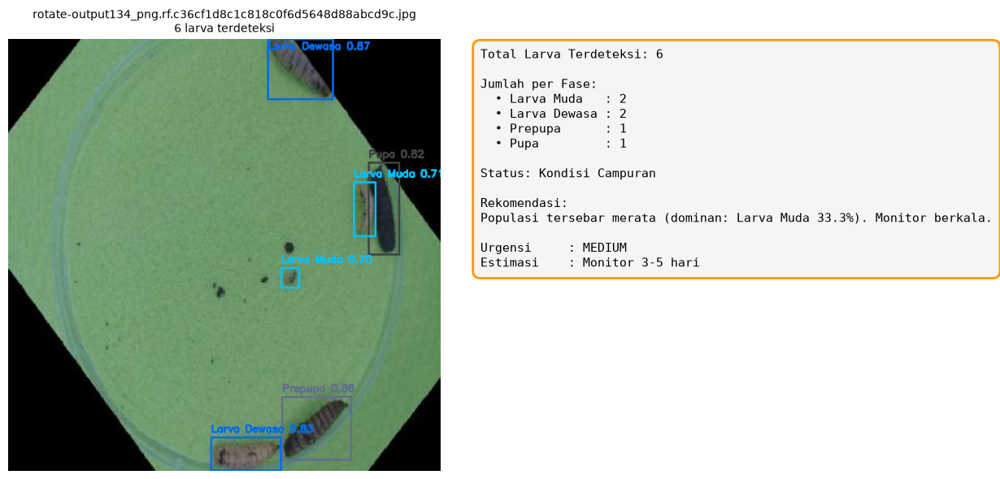

In [46]:
def visualize_with_recommendation(image_path, conf_threshold=0.25):
    """
    Menggabungkan hasil deteksi (bounding box) dengan rekomendasi waktu panen
    dalam satu gambar: panel kiri = citra + bbox, panel kanan = ringkasan rekomendasi.
    """
    # Jalankan pipeline lengkap (deteksi + ciri visual + rekomendasi)
    result_json = full_analysis_pipeline(image_path, conf_threshold)
    img_rgb, n_det = visualize_detection_result(image_path, conf_threshold)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.3, 1]})

    # Panel kiri: citra dengan bounding box
    axes[0].imshow(img_rgb)
    axes[0].set_title(f"{Path(image_path).name}\n{n_det} larva terdeteksi", fontsize=10)
    axes[0].axis("off")

    # Panel kanan: ringkasan rekomendasi (sebagai teks, bukan plot)
    axes[1].axis("off")
    rec = result_json["harvest_recommendation"]
    counts = result_json["phase_counts"]

    urgensi_color = {
        "low": "#4CAF50", "medium": "#FF9800",
        "high": "#F44336", "critical": "#B71C1C", "none": "#9E9E9E"
    }
    color = urgensi_color.get(rec.get("urgensi", "none"), "#000000")

    info_text = (
        f"Total Larva Terdeteksi: {result_json['total_larvae_detected']}\n\n"
        f"Jumlah per Fase:\n"
        f"  • Larva Muda   : {counts['Larva Muda']}\n"
        f"  • Larva Dewasa : {counts['Larva Dewasa']}\n"
        f"  • Prepupa      : {counts['Prepupa']}\n"
        f"  • Pupa         : {counts['Pupa']}\n\n"
        f"Status: {rec['status']}\n\n"
        f"Rekomendasi:\n{rec['rekomendasi']}\n\n"
        f"Urgensi     : {rec['urgensi'].upper()}\n"
        f"Estimasi    : {rec.get('estimasi_hari', '-')}"
    )

    axes[1].text(0.02, 0.98, info_text, transform=axes[1].transAxes,
                 fontsize=11, va="top", ha="left", family="monospace",
                 bbox=dict(boxstyle="round,pad=0.6", facecolor="#f5f5f5",
                           edgecolor=color, linewidth=2))

    plt.tight_layout()
    plt.savefig(f"outputs/rekomendasi_{Path(image_path).stem}.png", dpi=150, bbox_inches="tight")
    plt.show()

    return result_json


# --- Contoh pemakaian: coba beberapa citra test sampai dapat kasus dengan >1 larva ---
test_images = list(paths["test"]["images"].glob("*.*"))
random.shuffle(test_images)

contoh_terpakai = 0
for img_path in test_images:
    detections, _ = detect_larvae(img_path)
    if len(detections) >= 3:   # ambil citra yang punya cukup larva agar rekomendasi lebih representatif
        print(f"=== {img_path.name} ===")
        visualize_with_recommendation(img_path)
        contoh_terpakai += 1
    if contoh_terpakai >= 3:   # ambil 3 contoh berbeda
        break

In [47]:
import numpy as np

# Ambil satu contoh crop larva dari hasil deteksi pada data uji
sample_img_path = list(paths["test"]["images"].glob("*.*"))[0]
detections, orig_img = detect_larvae(sample_img_path, conf_threshold=0.25)

if len(detections) > 0:
    # Ambil larva pertama yang terdeteksi
    det = detections[0]
    x1, y1, x2, y2 = det["bbox"]
    crop_img = orig_img[y1:y2, x1:x2]

    print(f"Citra sampel: {sample_img_path.name}")
    print(f"Fase terdeteksi: {det['class_name']}  (confidence: {det['confidence']:.2f})")
    print(f"Ukuran crop: {crop_img.shape[1]}x{crop_img.shape[0]} piksel\n")

    # Jalankan K-Means (fungsi asli notebook, Cell 24)
    dominant_rgb = get_dominant_color(crop_img, k=3, max_iter=20, epsilon=0.5)
    R, G, B = dominant_rgb

    brightness = (R + G + B) / 3
    nama_warna = classify_color_name(R, G, B)

    print(f"Warna dominan hasil K-Means (R, G, B): ({R}, {G}, {B})")
    print(f"Brightness = (R+G+B)/3 = ({R}+{G}+{B})/3 = {brightness:.2f}")
    print(f"Kategori warna: {nama_warna}")
else:
    print("Tidak ada larva terdeteksi pada citra ini, coba citra lain.")

Citra sampel: nvcamtest_10067_s00_00051_jpg.rf.6a436334a7e8742ca82279662bead841.jpg
Fase terdeteksi: Larva Dewasa  (confidence: 0.86)
Ukuran crop: 106x97 piksel

Warna dominan hasil K-Means (R, G, B): (82, 121, 69)
Brightness = (R+G+B)/3 = (82+121+69)/3 = 90.67
Kategori warna: coklat gelap


Ditemukan 6 contoh kasus deteksi tidak sesuai label

nvcamtest_8469_s00_00026_jpg.rf.5ae362902383ac9a79a54d9914b033d2.jpg
  Label asli   : 6 larva, kelas: ['Larva Muda', 'Larva Dewasa', 'Prepupa', 'Pupa']
  Hasil deteksi: 5 larva, kelas: ['Larva Muda', 'Larva Dewasa', 'Prepupa', 'Pupa']

nvcamtest_12254_s00_00025_jpg.rf.65db2c947e0987a7f79e6c39625af864.jpg
  Label asli   : 26 larva, kelas: ['Larva Muda', 'Larva Dewasa']
  Hasil deteksi: 5 larva, kelas: ['Larva Dewasa']

nvcamtest_12254_s00_00030_jpg.rf.d7285c61d0fe3b7dd6ce4e1699ec93de.jpg
  Label asli   : 31 larva, kelas: ['Larva Muda', 'Larva Dewasa']
  Hasil deteksi: 1 larva, kelas: ['Larva Dewasa']

nvcamtest_8469_s00_00046_jpg.rf.b818aa1518ad4f29e93e64b469a28b4d.jpg
  Label asli   : 6 larva, kelas: ['Larva Muda', 'Larva Dewasa', 'Prepupa', 'Pupa']
  Hasil deteksi: 4 larva, kelas: ['Larva Dewasa', 'Prepupa']

nvcamtest_8668_s00_00023_jpg.rf.2f5bdaab373c04d15c09419fb965e6f4.jpg
  Label asli   : 8 larva, kelas: ['Larva Muda']
  Hasil 

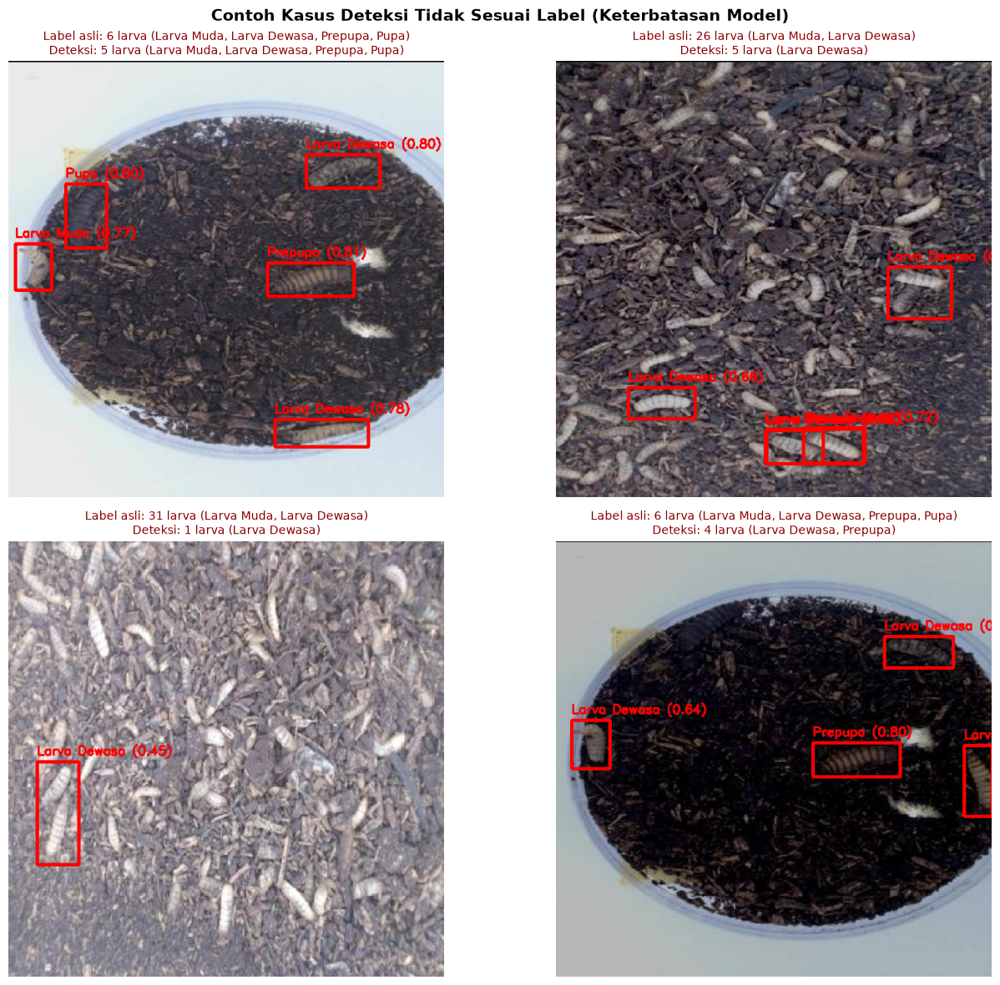

In [48]:
import cv2
import matplotlib.pyplot as plt
import random

random.seed(1)

# ============================================================
# Cari beberapa contoh dari data TEST yang deteksinya SALAH
# (bandingkan hasil deteksi model vs label asli/ground truth)
# ============================================================
contoh_salah = []
test_images = list(paths["test"]["images"].glob("*.*"))
random.shuffle(test_images)

for img_path in test_images:
    label_path = paths["test"]["labels"] / f"{img_path.stem}.txt"
    if not label_path.exists():
        continue

    # Ground truth (label asli)
    rows_gt = read_yolo_label(label_path)
    kelas_gt = set(int(r[0]) for r in rows_gt)

    # Hasil deteksi model
    detections, orig_img = detect_larvae(img_path, conf_threshold=0.25)
    kelas_pred = set(d["class_id"] for d in detections)

    # Kasus salah: jumlah deteksi beda, ATAU kelas yang terdeteksi beda dari label asli,
    # ATAU tidak ada yang terdeteksi sama sekali padahal ada label
    if len(detections) != len(rows_gt) or kelas_gt != kelas_pred:
        contoh_salah.append({
            "path": img_path,
            "detections": detections,
            "orig_img": orig_img,
            "jumlah_gt": len(rows_gt),
            "jumlah_pred": len(detections),
            "kelas_gt": [CLASS_NAMES[k] for k in kelas_gt],
            "kelas_pred": [CLASS_NAMES[k] for k in kelas_pred],
        })
    if len(contoh_salah) >= 6:
        break

print(f"Ditemukan {len(contoh_salah)} contoh kasus deteksi tidak sesuai label\n")
for c in contoh_salah:
    print(f"{c['path'].name}")
    print(f"  Label asli   : {c['jumlah_gt']} larva, kelas: {c['kelas_gt']}")
    print(f"  Hasil deteksi: {c['jumlah_pred']} larva, kelas: {c['kelas_pred']}")
    print()

# ============================================================
# Visualisasikan 4 contoh pertama
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, c in zip(axes, contoh_salah[:4]):
    img_with_box = c["orig_img"].copy()
    for det in c["detections"]:
        x1, y1, x2, y2 = det["bbox"]
        cv2.rectangle(img_with_box, (x1, y1), (x2, y2), (0, 0, 255), 3)
        cv2.putText(img_with_box, f"{det['class_name']} ({det['confidence']:.2f})",
                    (x1, max(y1-10, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    ax.imshow(cv2.cvtColor(img_with_box, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Label asli: {c['jumlah_gt']} larva ({', '.join(c['kelas_gt'])})\n"
                 f"Deteksi: {c['jumlah_pred']} larva ({', '.join(c['kelas_pred'])})",
                 fontsize=10, color="darkred")
    ax.axis("off")

plt.suptitle("Contoh Kasus Deteksi Tidak Sesuai Label (Keterbatasan Model)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/contoh_deteksi_salah.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

 No.                                                            Nama File Fase Sebenarnya Hasil Prediksi Status
   1         rotate-output137_png.rf.0fb300ed83ff3e483f02be511612af1b.jpg            Pupa           Pupa  Benar
   2 nvcamtest_7987_s00_00056_jpg.rf.0480d8ff8b0fbf54b114c7ffdd44321a.jpg    Larva Dewasa   Larva Dewasa  Benar
   3         rotate-output233_png.rf.d9603cca83eea6c70283a0dfc820f023.jpg            Pupa           Pupa  Benar
   4         rotate-output212_png.rf.a6f9c2e11a16eac9cadb97394b439cb1.jpg    Larva Dewasa   Larva Dewasa  Benar
   5           rotate-output1_png.rf.d71009c1b40b7793deb2790da3dc9b54.jpg    Larva Dewasa   Larva Dewasa  Benar
   6         rotate-output154_png.rf.8b1d9da7e702ef268af8810af70d350b.jpg         Prepupa        Prepupa  Benar


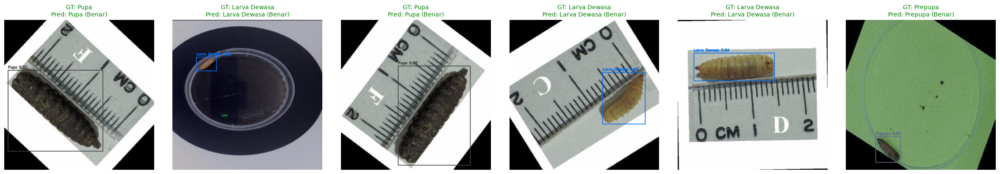

In [49]:
import random
import pandas as pd
import matplotlib.pyplot as plt

def ambil_fase_ground_truth_dominan(label_path, img_w, img_h):
    """
    Ambil fase yang paling dominan (jumlah larva terbanyak) sebagai
    'fase sebenarnya' representatif untuk satu citra.
    """
    rows = read_yolo_label(label_path)
    if not rows:
        return None
    kelas_ids = [int(r[0]) for r in rows]
    kelas_terbanyak = Counter(kelas_ids).most_common(1)[0][0]
    return CLASS_NAMES[kelas_terbanyak]

def ambil_fase_prediksi_dominan(detections):
    """Ambil fase yang paling dominan dari hasil deteksi model."""
    if not detections:
        return "Tidak Terdeteksi"
    nama_kelas = [d["class_name"] for d in detections]
    return Counter(nama_kelas).most_common(1)[0][0]


# --- Pilih beberapa sampel citra dari test set secara acak ---
random.seed(42)
sample_images = random.sample(
    list(paths["test"]["images"].glob("*.*")),
    min(6, len(list(paths["test"]["images"].glob("*.*"))))
)

hasil_tabel = []
for i, img_path in enumerate(sample_images, start=1):
    label_path = paths["test"]["labels"] / f"{img_path.stem}.txt"
    if not label_path.exists():
        continue

    # Jalankan deteksi menggunakan model (fungsi sudah ada di notebook, Cell 44)
    detections, orig_img = detect_larvae(img_path, conf_threshold=0.25)
    img_h, img_w = orig_img.shape[:2]

    fase_sebenarnya = ambil_fase_ground_truth_dominan(label_path, img_w, img_h)
    fase_prediksi = ambil_fase_prediksi_dominan(detections)
    status = "Benar" if fase_sebenarnya == fase_prediksi else "Salah"

    hasil_tabel.append({
        "No.": i,
        "Nama File": img_path.name,
        "Fase Sebenarnya": fase_sebenarnya,
        "Hasil Prediksi": fase_prediksi,
        "Status": status
    })

# --- Tampilkan sebagai tabel ---
df_hasil = pd.DataFrame(hasil_tabel)
print(df_hasil.to_string(index=False))

# --- Simpan juga sebagai gambar visual (opsional, untuk lampiran skripsi) ---
fig, axes = plt.subplots(1, len(sample_images), figsize=(4 * len(sample_images), 4))
if len(sample_images) == 1:
    axes = [axes]

for ax, row, img_path in zip(axes, hasil_tabel, sample_images):
    img_rgb, _ = visualize_detection_result(img_path, conf_threshold=0.25)
    ax.imshow(img_rgb)
    warna_judul = "green" if row["Status"] == "Benar" else "red"
    ax.set_title(f"GT: {row['Fase Sebenarnya']}\nPred: {row['Hasil Prediksi']} ({row['Status']})",
                 fontsize=10, color=warna_judul)
    ax.axis("off")

plt.tight_layout()
plt.savefig("tabel_4_3_pengujian_kualitatif.png", dpi=200, bbox_inches="tight")
plt.show()

Citra sampel: nvcamtest_10067_s00_00051_jpg.rf.6a436334a7e8742ca82279662bead841.jpg
Fase terdeteksi: Larva Dewasa (confidence: 0.86)
Ukuran crop asli: 106x97 piksel

Total piksel setelah resize 50x50: 2500 piksel

Contoh 5 piksel pertama (R, G, B):
  Piksel 1: R=89, G=130, B=74
  Piksel 2: R=90, G=131, B=75
  Piksel 3: R=89, G=130, B=74
  Piksel 4: R=90, G=131, B=75
  Piksel 5: R=89, G=130, B=74

Hasil akhir K-Means (3 cluster):
  Cluster 0: RGB=(66, 80, 54)  jumlah anggota = 767 piksel  (30.7% dari total)
  Cluster 1: RGB=(43, 47, 27)  jumlah anggota = 536 piksel  (21.4% dari total)
  Cluster 2: RGB=(81, 121, 69)  jumlah anggota = 1197 piksel  (47.9% dari total)

Cluster dominan terpilih: Cluster 2 (anggota terbanyak: 1197 piksel)
RGB dominan = (81, 121, 69)

Brightness = (81+121+69)/3 = 271/3 = 90.33
Kategori warna: coklat gelap

Variansi Laplacian: 42.72


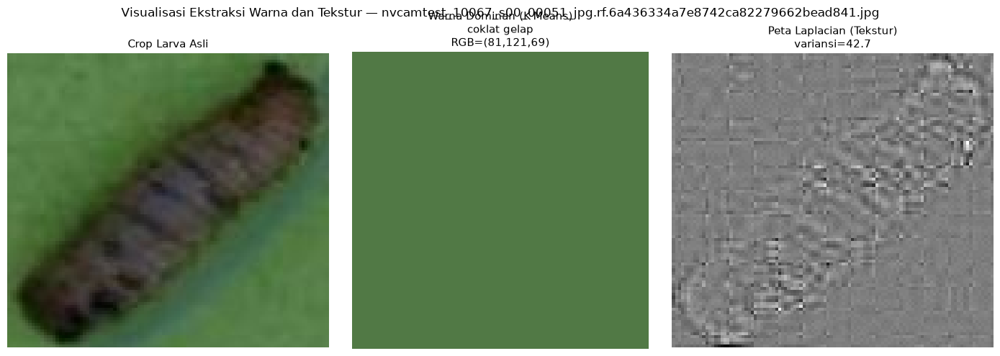

In [50]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Pastikan fungsi-fungsi berikut sudah dimuat sebelumnya:
# model (Cell 20/39), get_dominant_color & classify_color_name & analyze_texture (Cell 24), 
# detect_larvae (Cell 49)

# --- Ambil satu larva hasil deteksi sungguhan dari data uji ---
sample_img_path = list(paths["test"]["images"].glob("*.*"))[0]
detections, orig_img = detect_larvae(sample_img_path, conf_threshold=0.25)

if len(detections) > 0:
    det = detections[0]
    x1, y1, x2, y2 = det["bbox"]
    crop_img = orig_img[y1:y2, x1:x2]

    print(f"Citra sampel: {sample_img_path.name}")
    print(f"Fase terdeteksi: {det['class_name']} (confidence: {det['confidence']:.2f})")
    print(f"Ukuran crop asli: {crop_img.shape[1]}x{crop_img.shape[0]} piksel\n")

    # === WARNA DOMINAN (K-MEANS) ===
    img_small = cv2.resize(crop_img, (50, 50))
    pixels = img_small.reshape(-1, 3).astype(np.float32)
    print(f"Total piksel setelah resize 50x50: {pixels.shape[0]} piksel\n")

    print("Contoh 5 piksel pertama (R, G, B):")
    for i in range(5):
        b, g, r = pixels[i]
        print(f"  Piksel {i+1}: R={int(r)}, G={int(g)}, B={int(b)}")
    print()

    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.5)
    compactness, labels, centers = cv2.kmeans(
        pixels, 3, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS
    )

    unique, counts = np.unique(labels, return_counts=True)
    print("Hasil akhir K-Means (3 cluster):")
    for idx, cnt in zip(unique, counts):
        b, g, r = centers[idx]
        print(f"  Cluster {idx}: RGB=({int(r)}, {int(g)}, {int(b)})  "
              f"jumlah anggota = {cnt} piksel  "
              f"({cnt/pixels.shape[0]*100:.1f}% dari total)")

    cluster_dominan_idx = unique[np.argmax(counts)]
    b_dom, g_dom, r_dom = centers[cluster_dominan_idx]
    R, G, B = int(r_dom), int(g_dom), int(b_dom)

    print(f"\nCluster dominan terpilih: Cluster {cluster_dominan_idx} "
          f"(anggota terbanyak: {counts.max()} piksel)")
    print(f"RGB dominan = ({R}, {G}, {B})\n")

    brightness = (R + G + B) / 3
    print(f"Brightness = ({R}+{G}+{B})/3 = {R+G+B}/3 = {brightness:.2f}")

    nama_warna = classify_color_name(R, G, B)
    print(f"Kategori warna: {nama_warna}\n")

    # === TEKSTUR (LAPLACIAN VARIANCE) ===
    gray = cv2.cvtColor(crop_img, cv2.COLOR_BGR2GRAY)
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    variansi = laplacian.var()
    kategori_tekstur = analyze_texture(crop_img)  # sesuaikan jika return-nya berbeda
    print(f"Variansi Laplacian: {variansi:.2f}")

    # === VISUALISASI (gaya sama seperti Gambar 3.7) ===
    warna_swatch = np.full((100, 100, 3), (R, G, B), dtype=np.uint8)  # RGB murni

    fig, axes = plt.subplots(1, 3, figsize=(14, 5))

    axes[0].imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Crop Larva Asli", fontsize=11)
    axes[0].axis("off")

    axes[1].imshow(warna_swatch)
    axes[1].set_title(f"Warna Dominan (K-Means)\n{nama_warna}\nRGB=({R},{G},{B})", fontsize=11)
    axes[1].axis("off")

    im = axes[2].imshow(laplacian, cmap="gray")
    axes[2].set_title(f"Peta Laplacian (Tekstur)\nvariansi={variansi:.1f}", fontsize=11)
    axes[2].axis("off")

    plt.suptitle(f"Visualisasi Ekstraksi Warna dan Tekstur — {sample_img_path.name}", fontsize=12)
    plt.tight_layout()
    plt.savefig("outputs/gambar_3_7_ekstraksi_warna_tekstur_baru.png", dpi=200, bbox_inches="tight")
    plt.show()

else:
    print("Tidak ada larva terdeteksi. Coba ganti index citra sampel, "
          "misalnya list(paths['test']['images'].glob('*.*'))[5]")

In [51]:
from collections import defaultdict
import numpy as np

variansi_per_fase = defaultdict(list)

# Ambil beberapa sampel dari tiap fase pada data uji
sample_images = list(paths["test"]["images"].glob("*.*"))[:100]  # cek 100 citra pertama

for img_path in sample_images:
    detections, orig_img = detect_larvae(img_path, conf_threshold=0.25)
    for det in detections:
        x1, y1, x2, y2 = det["bbox"]
        crop_img = orig_img[y1:y2, x1:x2]
        if crop_img.size == 0:
            continue

        gray = cv2.cvtColor(crop_img, cv2.COLOR_BGR2GRAY)
        laplacian = cv2.Laplacian(gray, cv2.CV_64F)
        variansi = laplacian.var()

        variansi_per_fase[det["class_name"]].append(variansi)

# Cetak ringkasan statistik per fase
print(f"{'Fase':<15}{'Jumlah':>8}{'Min':>10}{'Max':>10}{'Rata-rata':>12}")
print("-" * 55)
for fase in CLASS_NAMES:
    nilai = variansi_per_fase.get(fase, [])
    if nilai:
        print(f"{fase:<15}{len(nilai):>8}{min(nilai):>10.1f}{max(nilai):>10.1f}{np.mean(nilai):>12.1f}")
    else:
        print(f"{fase:<15}{'(tidak ada data pada sampel ini)'}")

Fase             Jumlah       Min       Max   Rata-rata
-------------------------------------------------------
Larva Muda           67      32.3    1051.8       214.3
Larva Dewasa         88      33.7     515.0       192.5
Prepupa              31      47.1     200.9       119.7
Pupa                 20      44.9     197.6       100.0


Citra sampel: nvcamtest_10067_s00_00051_jpg.rf.6a436334a7e8742ca82279662bead841.jpg
Fase terdeteksi: Larva Dewasa (confidence: 0.86)
RGB dominan: (67, 67, 57)
Brightness: 63.67
Kategori warna: coklat gelap


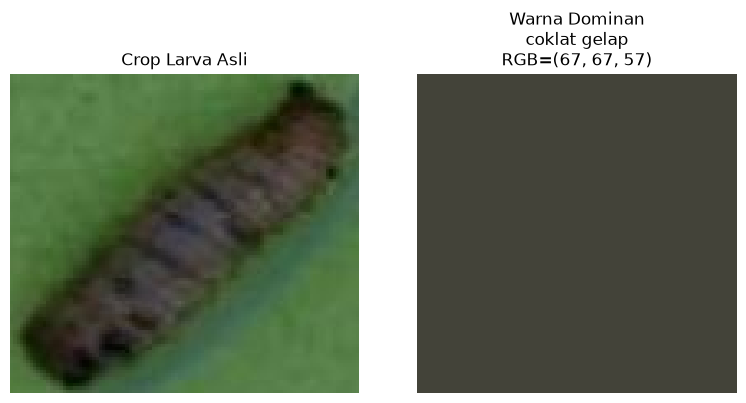

In [52]:
def get_dominant_color(crop_img, k=3, max_iter=20, epsilon=0.5, center_ratio=0.6):
    """
    Ekstraksi warna dominan menggunakan K-Means, hanya pada area TENGAH crop
    (60% dari ukuran asli) untuk mengurangi pengaruh latar belakang.
    """
    h, w = crop_img.shape[:2]
    margin_h = int(h * (1 - center_ratio) / 2)
    margin_w = int(w * (1 - center_ratio) / 2)
    crop_tengah = crop_img[margin_h:h-margin_h, margin_w:w-margin_w]
    if crop_tengah.size == 0:
        crop_tengah = crop_img
    img_small = cv2.resize(crop_tengah, (50, 50))
    pixels = img_small.reshape(-1, 3).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, max_iter, epsilon)
    _, labels, centers = cv2.kmeans(pixels, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    unique, counts = np.unique(labels, return_counts=True)
    idx = unique[np.argmax(counts)]
    b, g, r = centers[idx]
    return (int(r), int(g), int(b))


# --- Uji pada citra sampel ---
sample_img_path = list(paths["test"]["images"].glob("*.*"))[0]
detections, orig_img = detect_larvae(sample_img_path, conf_threshold=0.25)
det = detections[0]
x1, y1, x2, y2 = det["bbox"]
crop_img = orig_img[y1:y2, x1:x2]

rgb_dominan = get_dominant_color(crop_img, k=3)
nama_warna = classify_color_name(*rgb_dominan)
brightness = sum(rgb_dominan) / 3

print(f"Citra sampel: {sample_img_path.name}")
print(f"Fase terdeteksi: {det['class_name']} (confidence: {det['confidence']:.2f})")
print(f"RGB dominan: {rgb_dominan}")
print(f"Brightness: {brightness:.2f}")
print(f"Kategori warna: {nama_warna}")

# --- Visualisasi hasil (tanpa perbandingan, cukup 2 panel) ---
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Crop Larva Asli")

swatch = np.full((100, 100, 3), rgb_dominan, dtype=np.uint8)
axes[1].imshow(swatch)
axes[1].set_title(f"Warna Dominan\n{nama_warna}\nRGB={rgb_dominan}")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("outputs/gambar_3_7_warna_dominan_final.png", dpi=200, bbox_inches="tight")
plt.show()

In [53]:
# --- Ambil crop dari citra sampel (pastikan sudah ada crop_img dari sel sebelumnya) ---
h, w = crop_img.shape[:2]
center_ratio = 0.6
margin_h = int(h * (1 - center_ratio) / 2)
margin_w = int(w * (1 - center_ratio) / 2)
crop_tengah = crop_img[margin_h:h-margin_h, margin_w:w-margin_w]

if crop_tengah.size == 0:
    crop_tengah = crop_img

print(f"Ukuran crop asli: {w}x{h} piksel")
print(f"Ukuran crop tengah (60%): {crop_tengah.shape[1]}x{crop_tengah.shape[0]} piksel\n")

# --- Jalankan K-Means dan lihat detail tiap cluster ---
img_small = cv2.resize(crop_tengah, (50, 50))
pixels = img_small.reshape(-1, 3).astype(np.float32)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.5)
_, labels, centers = cv2.kmeans(pixels, 3, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

unique, counts = np.unique(labels, return_counts=True)
print("Hasil clustering K-Means pada area tengah (60%):")
for idx, cnt in zip(unique, counts):
    b, g, r = centers[idx]
    print(f"  Cluster {idx}: RGB=({int(r)}, {int(g)}, {int(b)})  "
          f"jumlah anggota = {cnt} piksel  ({cnt/pixels.shape[0]*100:.1f}%)")

# --- Tentukan cluster dominan ---
cluster_dominan_idx = unique[np.argmax(counts)]
b_dom, g_dom, r_dom = centers[cluster_dominan_idx]
print(f"\nCluster dominan: Cluster {cluster_dominan_idx} "
      f"(RGB=({int(r_dom)},{int(g_dom)},{int(b_dom)}), anggota terbanyak={counts.max()} piksel)")

Ukuran crop asli: 106x97 piksel
Ukuran crop tengah (60%): 64x59 piksel

Hasil clustering K-Means pada area tengah (60%):
  Cluster 0: RGB=(49, 52, 32)  jumlah anggota = 788 piksel  (31.5%)
  Cluster 1: RGB=(66, 67, 57)  jumlah anggota = 930 piksel  (37.2%)
  Cluster 2: RGB=(72, 108, 61)  jumlah anggota = 782 piksel  (31.3%)

Cluster dominan: Cluster 1 (RGB=(66,67,57), anggota terbanyak=930 piksel)


---
## 8. Ekspor Model ke TensorFlow Lite

Model PyTorch (.pt) dikonversi ke TensorFlow Lite (.tflite) melalui jalur **PyTorch -> ONNX -> TensorFlow -> TFLite**, agar dapat dijalankan secara *on-device* di aplikasi Flutter tanpa memerlukan server maupun koneksi internet.

Tensor input hasil konversi berukuran `[1, 640, 640, 3]` (format NHWC, nilai piksel ternormalisasi 0-1), dan tensor output berukuran `[1, 8, 8400]` — yaitu 4 nilai koordinat bounding box (cx, cy, w, h) + 4 skor confidence per kelas, untuk 8.400 kandidat prediksi pada seluruh grid & skala resolusi.

In [54]:
RUN_TFLITE_EXPORT = False  

if RUN_TFLITE_EXPORT:
    onnx_path = model.export(format="onnx", imgsz=640, simplify=True)
    print("ONNX berhasil diekspor ke:", onnx_path)
    print("Lanjutkan konversi ONNX->TFLite di terminal dengan:")
    print(f"  onnx2tf -i {onnx_path} -o tflite_model_output")
else:
    print("RUN_TFLITE_EXPORT=False, melewati ekspor.")


RUN_TFLITE_EXPORT=False, melewati ekspor.


In [55]:
tflite_files = list(Path("tflite_model_output").rglob("*.tflite")) if Path("tflite_model_output").exists() else []
print("File TFLite ditemukan:")
for f in tflite_files:
    print(f, "-", round(f.stat().st_size / 1e6, 2), "MB")


File TFLite ditemukan:
tflite_model_output\best_float16.tflite - 18.96 MB
tflite_model_output\best_float32.tflite - 37.84 MB


In [56]:
import cv2
from pathlib import Path

# ambil 1 citra contoh dari train set
sample_img_path = list(paths["train"]["images"].glob("*.*"))[0]
img = cv2.imread(str(sample_img_path))
H, W = img.shape[:2]
print(f"File: {sample_img_path.name}")
print(f"Lebar (W) = {W}, Tinggi (H) = {H}")

File: -_jpg.rf.400e05222c259011470d1261082c2db1.jpg
Lebar (W) = 640, Tinggi (H) = 640


In [57]:
import pandas as pd

results_csv = TRAINED_RUN_DIR / "results.csv"  # sesuaikan variabel run dir Anda
df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()

# ambil baris epoch terakhir sebagai contoh real
row = df.iloc[-1]
print("Epoch:", int(row['epoch']))
print("train/box_loss:", row['train/box_loss'])
print("train/cls_loss:", row['train/cls_loss'])
print("train/dfl_loss:", row['train/dfl_loss'])

Epoch: 120
train/box_loss: 0.84064
train/cls_loss: 0.29237
train/dfl_loss: 0.97768


---
## Ringkasan

| Tahap Pipeline | Metode/Algoritma | Peran |
|---|---|---|
| Pengumpulan Data | Roboflow Universe (BSF Larvae CV Dataset) | Menyediakan citra & anotasi mentah 6 kelas instar |
| Preprocessing Data | Remapping kelas, Split data, Normalisasi, Letterbox, Augmentasi (HSV, Rotasi, Mosaic, Mixup, Copy-Paste) | Menyiapkan data konsisten & bervariasi untuk training |
| Ekstraksi Fitur | Backbone YOLOv11s (CNN) + K-Means Clustering (warna) + Laplacian Variance (tekstur) | Mengekstrak fitur spasial, warna dominan, dan kekasaran permukaan larva |
| Pelatihan Model | YOLOv11s (Backbone-Neck-Head, anchor-free, DFL), optimizer AdamW | Melatih model mendeteksi & mengklasifikasi 4 fase larva |
| Pengujian | Precision, Recall, mAP, Confusion Matrix pada test set | Mengukur performa model pada data yang belum pernah dilihat |
| Klasifikasi | Deteksi YOLOv11 + ciri visual + rule-based reasoning | Mengklasifikasikan fase tiap larva & menghasilkan rekomendasi waktu panen |
| Deployment | Konversi PyTorch -> ONNX -> TFLite | Menjalankan model secara on-device di Flutter |
